# 5주차 · 우주발사체의 유도 · 항법 · 제어
## Navigation, Guidance and Control of Space Launch Vehicles

**우주수송정책과 발사체 기술** · 대학원 강의노트 (실습형 Jupyter Notebook)

---

- 로켓방정식 = **가능성**, 유도·항법·제어(GNC) = 가능성을 **실제 궤도**로 전환하는 수단
- 본 노트북 = 양자 간 간극을 이론·수식·수치실습으로 연결

| 부(部) | 핵심 질문 | 주요 실습 |
|---|---|---|
| **제0부** 서론 | 왜 로켓 이론과 함께 GNC를 보는가 | ΔV 손실항 분해 |
| **제1부** 개관 | 항법·유도·제어는 무엇을 나누어 맡는가 | GNC 블록선도 작도 |
| **제2부** 항법 | 발사체는 자기 위치를 어떻게 아는가 | 스트랩다운 적분, 오차 성장, 정렬, 칼만필터 |
| **제3부** 유도 | 어디로 가야 하는지 누가 정하는가 | 오차 예산, 바람 하중, **최적 조향법칙 수치해** |
| **제4부** 사례 | 실제 발사체는 어떤 선택을 했는가 | 누리호 2차 비행시험 결과 해석 |

> **사용법**
> - `Run All`로 전체 1회 실행 후, 각 절의 `연습` 셀에서 파라미터 변경 → 결과 변화 관찰
> - 모든 수치 결과는 셀 실행으로 재현 (하드코딩된 그림 없음)

---
## 제0부 · 환경 설정

- 공용 상수·유틸리티를 먼저 정의
- 이후 모든 셀이 본 셀에 의존

> **표기 방침**
> - 강의 서술(마크다운): **한글**
> - 코드 셀의 표·그림·출력 문구(제목·범례·축·캡션): **영어**
> - 사유: 한글 폰트가 없는 환경(Colab·서버·Windows/Mac 기본 설정 등)에서도 그림·표가 깨지지 않고 동일하게 표시
> - 각 코드 셀 상단의 `[Exercise N-M]` 번호 = 본문 절 번호와 대응

In [1]:
# =============================================================================
#  Part 0 - Setup   (run this cell first)
#  NOTE: All code output (tables, figures) is in ENGLISH on purpose, so that the
#        notebook renders identically on any machine (Colab / Windows / macOS)
#        without a Korean font installed. The lecture text is in Korean markdown.
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams["font.family"]       = "DejaVu Sans"   # available everywhere
matplotlib.rcParams["axes.unicode_minus"] = False
matplotlib.rcParams["figure.dpi"]         = 110
matplotlib.rcParams["savefig.bbox"]       = "tight"

# ---- house colors ----
NAVY, STEEL, AMBER, MUTED = "#102A43", "#486581", "#E0A526", "#627D98"
PALETTE = [NAVY, STEEL, AMBER, "#C0392B", "#7BA0C0"]

# ---- physical constants ----
g0      = 9.80665            # standard gravity            [m/s^2]
MU      = 3.986004418e14     # Earth gravitational param.  [m^3/s^2]
RE      = 6378.137e3         # Earth equatorial radius     [m]
OME     = 7.2921159e-5       # Earth rotation rate         [rad/s]
C_LIGHT = 2.99792458e8       # speed of light              [m/s]

def show(df, caption=None):
    # print a DataFrame without the index
    if caption:
        print(caption)
    with pd.option_context("display.max_columns", None, "display.width", 200):
        print(df.to_string(index=False))

print("Setup done | numpy", np.__version__, "| pandas", pd.__version__,
      "| matplotlib", matplotlib.__version__)

Setup done | numpy 2.5.3 | pandas 3.0.5 | matplotlib 3.11.2


---
# 서론 · 왜 「로켓 이론」과 함께 유도·항법·제어를 보는가

이상 로켓방정식이 답하지 못하는 세 가지 질문

### ① 방정식은 '가능성'만 제시
- Tsiolkovsky 식 = 추진제를 이상적으로 모두 소모했을 때 얻는 속도증분의 **상한**
- 그 속도를 *어느 방향으로* 쌓을지는 방정식 밖의 문제

### ② 손실항의 크기를 결정
- 실제 필요 ΔV = 중력손실 + 항력손실 + 조향손실
- **조향손실(steering loss)** = 전적으로 유도법칙이 만들어내는 항

### ③ 성능 산포를 흡수
- 추력·비추력·질량 = 3σ 수준의 산포 보유
- **폐루프 유도** = 산포를 실시간 흡수하여 목표궤도에 수렴시키는 유일한 장치

$$\Delta V_{ideal} = I_{sp}\,g_0 \ln\!\left(\frac{m_0}{m_f}\right)$$

$$\Delta V_{required} = \Delta V_{orbit} + \Delta V_{gravity} + \Delta V_{drag} + \Delta V_{steering}$$

> - 좌변(추진 성능)과 우변 첫 항(궤도역학) = 설계자의 선택
> - 뒤의 세 손실항 = 비행 중 **어떻게 조종하는가**에 의해 결정
> - → **유도·항법·제어는 로켓방정식의 나머지 절반**

| 관점 | 함의 |
|---|---|
| **설계** | 궤적·유도 설계 미확정 → 필요 ΔV 미확정 → 단 구성(staging)·이륙질량 미확정 |
| **정책** | 고성능 관성센서·유도 알고리즘 = 탄도미사일 기술과 물리적으로 동일 → GNC는 수출통제(MTCR)의 핵심 품목이자 국산화의 병목 |

== Typical dV budget for a LEO insertion mission (illustrative) ==
               Item  dV [m/s]                         Set by
   Orbital velocity      7800              Orbital mechanics
       Gravity loss      1200   Trajectory / guidance design
          Drag loss       150             Shape & trajectory
      Steering loss       100                   Guidance law
Earth rotation gain      -400 Launch site latitude & azimuth
TOTAL (required dV)      8850                              -

Required dV = 8,850 m/s  ->  mass ratio m0/mf = 20.25  (Isp = 300 s)
With zero losses                  m0/mf = 14.17
-> The 1,050 m/s of losses inflate the mass ratio by 1.43x.
-> Cutting steering loss by 100 m/s alone saves about 3,342 kg of propellant on a 100 t vehicle.


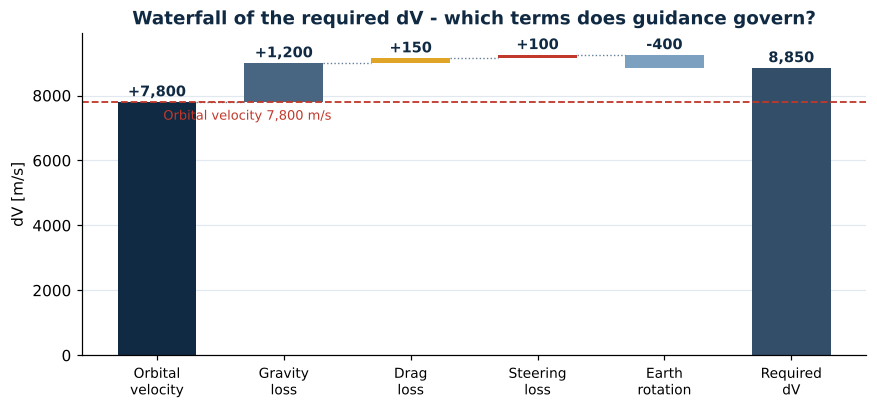

In [2]:
# [Exercise 0-1] Delta-V budget - the gap between the ideal rocket equation and reality
budget = pd.DataFrame({
    "Item":        ["Orbital velocity", "Gravity loss", "Drag loss", "Steering loss", "Earth rotation gain"],
    "dV [m/s]":    [7800, 1200, 150, 100, -400],
    "Set by":      ["Orbital mechanics", "Trajectory / guidance design", "Shape & trajectory",
                    "Guidance law", "Launch site latitude & azimuth"],
})
budget.loc[len(budget)] = ["TOTAL (required dV)", budget["dV [m/s]"].sum(), "-"]
show(budget, "== Typical dV budget for a LEO insertion mission (illustrative) ==")

dv_req   = budget["dV [m/s]"].iloc[-1]
Isp      = 300.0
mr       = np.exp(dv_req / (Isp * g0))
mr_orbit = np.exp(7800 / (Isp * g0))
print(f"\nRequired dV = {dv_req:,.0f} m/s  ->  mass ratio m0/mf = {mr:.2f}  (Isp = {Isp:.0f} s)")
print(f"With zero losses                  m0/mf = {mr_orbit:.2f}")
print(f"-> The {dv_req-7800:,.0f} m/s of losses inflate the mass ratio by {mr/mr_orbit:.2f}x.")
print(f"-> Cutting steering loss by 100 m/s alone saves about "
      f"{100e3*(1-np.exp(-100/(Isp*g0))):,.0f} kg of propellant on a 100 t vehicle.")

# waterfall: how each term stacks up to the required dV
vals = budget["dV [m/s]"][:-1].values.astype(float)
labs = ["Orbital\nvelocity", "Gravity\nloss", "Drag\nloss", "Steering\nloss", "Earth\nrotation"]
cum  = np.concatenate([[0], np.cumsum(vals)])
cols = [NAVY, STEEL, AMBER, "#C0392B", "#7BA0C0"]

fig, ax = plt.subplots(figsize=(9.2, 3.8))
for i, (v, c) in enumerate(zip(vals, cols)):
    bottom = cum[i] if v >= 0 else cum[i] + v
    ax.bar(i, abs(v), bottom=bottom, color=c, width=0.62)
    ax.text(i, max(cum[i], cum[i+1]) + 180, f"{v:+,.0f}", ha="center", fontsize=9.5,
            fontweight="bold", color=NAVY)
    if i < len(vals)-1:
        ax.plot([i+0.31, i+1-0.31], [cum[i+1]]*2, color=MUTED, lw=0.9, ls=":")
ax.bar(len(vals), cum[-1], color="#334E68", width=0.62)
ax.text(len(vals), cum[-1]+180, f"{cum[-1]:,.0f}", ha="center", fontsize=9.5,
        fontweight="bold", color=NAVY)
ax.axhline(7800, color="#C0392B", ls="--", lw=1.2)
ax.text(0.05, 7560, "Orbital velocity 7,800 m/s", fontsize=8.5, color="#C0392B", va="top")
ax.set_xticks(range(len(vals)+1)); ax.set_xticklabels(labs + ["Required\ndV"], fontsize=9)
ax.set_ylabel("dV [m/s]"); ax.set_ylim(0, cum[-1]*1.12)
ax.set_title("Waterfall of the required dV - which terms does guidance govern?",
             color=NAVY, fontweight="bold")
ax.grid(axis="y", color="#E2E8F0"); ax.set_axisbelow(True)
for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
plt.show()

---
## 학습목표

본 노트북 학습 후 **설명하고 계산할 수 있어야** 할 사항

1. **항법·유도·제어의 구분**
   - 세 기능이 각각 답하는 질문과 GNC 루프에서의 위치
   - 내루프/외루프의 대역폭 분리 원리
2. **관성항법의 원리와 오차 성장**
   - 자이로·가속도계의 측정량과 적분 구조
   - 센서 바이어스가 자세·속도·위치 오차로 $t,\ t^2,\ t^3$ 성장하는 과정의 정량화
3. **유도 법칙의 유래**
   - 최적제어 문제에서 이중선형 탄젠트 조향법칙이 도출되는 경로
   - 실제 발사체가 근사형을 사용하는 이유
4. **사례 기반 성능 해석**
   - 누리호 2차 비행시험 결과를 항법오차·유도오차·잔류추력 오차로 분해·해석
   - 국산화 과제 도출

> 본 자료 = 한국항공우주연구원 발사체 유도항법 강의자료(2024) 등 공개 문헌의 내용을 강의 목적에 맞게 재구성·재서술한 것 (상세 서지: 마지막 절)

---
# 제1부 · 유도·항법·제어 개관

> 대항해시대의 항해술에서 발사체 비행소프트웨어까지 — 세 기능은 왜 분리되었는가

## 1.1 세 개의 질문: 항법 · 유도 · 제어

- GNC = 단일 기능이 아니라 **성격이 다른 세 질문**에 대한 답의 결합

| 기능 | 질문 | 내용 |
|---|---|---|
| **항법 (Navigation)** | "나는 지금 어디에 있는가" | 각속도·비력(specific force) 측정값 → 현재 자세·속도·위치 벡터 결정. **측정과 계산의 문제**이며 그 자체로는 명령을 생성하지 않음 |
| **유도 (Guidance)** | "어디로 가야 하는가" | 현재 상태 → 목표 궤도 도달을 위한 방향·궤적 결정. 예측–수정(prediction–correction) 구조. 상대적으로 **느린 외루프(outer loop)** |
| **제어 (Control)** | "어떻게 그 방향을 유지하는가" | 유도 명령 추종을 위한 힘·모멘트 생성 + 기체 자세 안정성 유지. **빠른 내루프(inner loop)** = 안정화의 문제 |

### 역사적 기원
- 세 기능의 구분 = **항해술**에서 유래
  - 항법: 육분의로 별을 관측해 위치 산출
  - 유도: 해도 위에서 목적지까지의 새 침로 설정
  - 제어: 타륜을 돌려 침로 유지
  - → 선박에서는 **서로 다른 사람의 일**
- 초기 제트여객기(B-707, DC-8): 조종사와 별도로 항법사(navigator) 탑승
- 현재 발사체: 세 역할 모두 탑재컴퓨터의 **비행소프트웨어** 내에서 수행

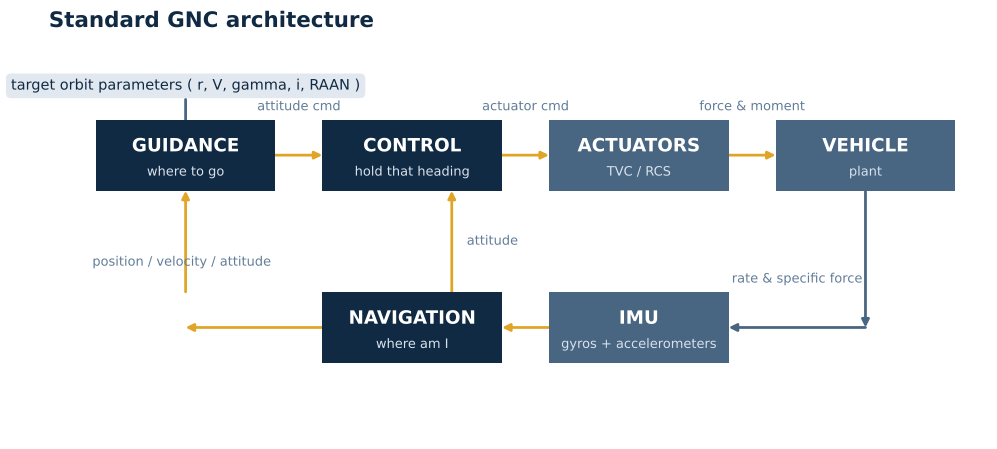

The dark-navy blocks (guidance, control, navigation) are NOT hardware:
they are functions inside the on-board computer's flight software.
Only the IMU, the actuators and the vehicle itself are physical.

Order matters: if navigation is wrong, guidance computes a correct answer to
the wrong question. Navigation performance therefore sets the UPPER BOUND on
insertion accuracy; guidance sophistication only operates inside that bound.


In [3]:
# [Exercise 1-1] Draw the standard GNC block diagram.
#   Commands flow left -> right; the state feeds back along the bottom -> left.

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.set_xlim(0, 12); ax.set_ylim(0, 5.2); ax.axis("off")

def block(x, y, w, h, title, sub, fc):
    ax.add_patch(plt.Rectangle((x, y), w, h, facecolor=fc, edgecolor="none", zorder=2))
    ax.text(x+w/2, y+h*0.62, title, ha="center", va="center", color="white",
            fontsize=12, fontweight="bold", zorder=3)
    ax.text(x+w/2, y+h*0.26, sub, ha="center", va="center", color="#D9E2EC", fontsize=8.5, zorder=3)

def arrow(x0, y0, x1, y1, color=AMBER, label=None, labxy=None):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=1.8, shrinkA=0, shrinkB=0), zorder=1)
    if label and labxy:
        ax.text(labxy[0], labxy[1], label, ha="center", va="center", fontsize=8.5, color=MUTED)

W, H = 2.3, 0.95
xs = [0.6, 3.5, 6.4, 9.3]; yT, yB = 3.3, 1.0
block(xs[0], yT, W, H, "GUIDANCE", "where to go",        NAVY)
block(xs[1], yT, W, H, "CONTROL",  "hold that heading",  NAVY)
block(xs[2], yT, W, H, "ACTUATORS", "TVC / RCS",         STEEL)
block(xs[3], yT, W, H, "VEHICLE",  "plant",              STEEL)
block(xs[1], yB, W, H, "NAVIGATION", "where am I",       NAVY)
block(xs[2], yB, W, H, "IMU", "gyros + accelerometers",  STEEL)

for i, lab in enumerate(["attitude cmd", "actuator cmd", "force & moment"]):
    arrow(xs[i]+W, yT+H/2, xs[i+1], yT+H/2, label=lab,
          labxy=((xs[i]+W + xs[i+1])/2, yT+H+0.17))
arrow(xs[3]+W/2, yT, xs[3]+W/2, yB+H/2, color=STEEL)
arrow(xs[3]+W/2, yB+H/2, xs[2]+W, yB+H/2, color=STEEL, label="rate & specific force",
      labxy=((xs[2]+W + xs[3]+W/2)/2, yB+H+0.17))
arrow(xs[2], yB+H/2, xs[1]+W, yB+H/2)
arrow(xs[1]+W*0.72, yB+H, xs[1]+W*0.72, yT, label="attitude",
      labxy=(xs[1]+W*0.72+0.52, (yB+H+yT)/2))
arrow(xs[1], yB+H/2, xs[0]+W/2, yB+H/2)
arrow(xs[0]+W/2, yB+H, xs[0]+W/2, yT, label="position / velocity / attitude",
      labxy=(xs[0]+W/2-0.05, (yB+H+yT)/2-0.28))
ax.text(xs[0]+W/2, yT+H+0.45, "target orbit parameters ( r, V, gamma, i, RAAN )",
        ha="center", va="center", fontsize=9.5, color=NAVY,
        bbox=dict(boxstyle="round,pad=0.35", facecolor="#E2E8F0", edgecolor="none"))
arrow(xs[0]+W/2, yT+H+0.27, xs[0]+W/2, yT, color=STEEL)
ax.set_title("Standard GNC architecture", fontsize=14, fontweight="bold", color=NAVY,
             loc="left", pad=14)
plt.show()

print("The dark-navy blocks (guidance, control, navigation) are NOT hardware:")
print("they are functions inside the on-board computer's flight software.")
print("Only the IMU, the actuators and the vehicle itself are physical.")
print()
print("Order matters: if navigation is wrong, guidance computes a correct answer to")
print("the wrong question. Navigation performance therefore sets the UPPER BOUND on")
print("insertion accuracy; guidance sophistication only operates inside that bound.")

## 1.2 내루프와 외루프: 왜 기능을 나누는가

- 설계의 출발점 = 대역폭이 다른 문제를 하나의 루프로 풀지 않음

| 구분 | 유도 (외루프) | 제어 (내루프) | 시퀀스 제어 |
|---|---|---|---|
| **다루는 물리량** | 위치·속도 벡터 (궤도 수준) | 자세각·각속도 (기체 수준) | 이산 사건 (단분리·점화) |
| **대표 주기** | 0.1 ~ 1 초급 | 수 ms ~ 수십 ms급 | 사건 기반(event-driven) |
| **목적함수** | 목표궤도 오차 최소화, 추진제 최소 소모 | 명령 추종, 자세 안정성 확보 | 정해진 순서·시각의 보장 |
| **실패의 결과** | 궤도 진입 실패 (임무 실패) | 기체 자세 발산 (즉시 상실) | 단분리 실패 등 치명적 사건 |
| **설계 도구** | 최적제어·궤적최적화 | 고전/현대 제어이론, 구조연성 해석 | 신뢰성·이중화 설계 |

### 주파수 분리(frequency separation)
- 내루프가 외루프보다 충분히 빠르면 → 유도는 제어 동역학 무시 가능
- 가정: **"명령한 자세는 즉시 실현된다"**
- 효과: 유도 문제를 **질점(point-mass) 궤적 문제**로 단순화

### 가정이 깨지는 지점
- 해당 조건: 추진제 슬로싱, 동체 굽힘모드(bending mode), 대형 저강성 기체
- 현상: 두 루프의 대역폭 접근
- → **초대형·재사용 발사체에서 GNC 설계가 어려워지는 근본 원인**

---
# 제2부 · 항법 (Navigation)

> 관성센서 · 스트랩다운 기법 · 오차 모델 · 초기정렬 · 위성항법 결합

## 2.1 항법 방식의 계보와 발사체의 선택

- 핵심 질문: 여섯 가지 항법 방식 중 발사체는 왜 관성항법을 택했는가

| 방식 | 원리 |
|---|---|
| 지문항법 (Piloting) | 지형지물을 눈으로 확인 |
| 추측항법 (Dead-Reckoning) | 침로·속력·시간으로 위치 추정 |
| 천측항법 (Celestial) | 천체 관측으로 절대위치 결정 |
| 전파항법 (Radio) | 지상국 전파를 기준으로 측위 |
| **관성항법 (INS)** | **가속도·각속도 적분으로 자립 측위** |
| **위성항법 (GNSS)** | **위성 신호로 절대위치 측정** |

| 특성 | 관성항법 (INS) | 위성항법 (GNSS) |
|---|---|---|
| 정확도 특성 | 단기 정확, 시간에 따라 열화 | 장기 안정, 단기 잡음 큼 |
| 초기조건 | **필수 (초기정렬)** | 불필요 |
| 자세 정보 | **제공** | 일반적으로 미제공 |
| 중력 영향 | 받음 (중력모델 필요) | 받지 않음 |
| 자립성 | 완전 자립 | 외부 신호 의존 |
| 재밍 내성 | 있음 | 없음 |
| 출력 주기 | 높음 (수백 Hz) | 낮음 (수 Hz) |

> **발사체가 관성항법을 택하는 세 조건**
> - 상승 구간이 10분 내외로 **짧음**
> - 외부 신호 의존 불가 (재밍·차폐·자세 급변)
> - **자세 정보가 제어에 필수**
> - → 세 조건이 겹치면 선택지는 관성항법 하나로 수렴
> - 위성항법 = '대체재'가 아닌 장기 드리프트를 억제하는 **'보강재'**

## 2.2 관성항법의 세 가지 구성요소

- 출발점: 센서가 주는 것과 **주지 않는 것**의 구분

1. **관성측정장치 (IMU)** — 자이로 3축(각속도) + 가속도계 3축(**비력** specific force)
   - 가속도계 = '가속도'가 아닌 **중력을 제외한 비중력 가속도**를 측정
   - 자유낙하 중인 가속도계의 출력 = 0
2. **초기조건** — 자세·속도·위치의 초기값
   - 적분기는 초기값 없이 아무것도 산출하지 못함
   - → 발사 전 **초기정렬(alignment)** 필요 (GNSS와의 결정적 차이)
3. **중력모델** — 가속도계가 측정하지 못하는 중력항 $\mathbf{g}$를 계산으로 보충
   - WGS-84 타원체 + 구면조화 전개($J_2\!\cdot\!J_3\!\cdot\!J_4$) 사용

$$\mathbf{a} = \frac{\mathbf{F}}{m} + \mathbf{g}$$

- 가속도계 출력 $\mathbf{F}/m$ + 중력모델 $\mathbf{g}$ = 관성좌표계 가속도
- 자세: 자이로 적분 / 속도·위치: 가속도의 1회·2회 적분
- 관성항법이 **'적분의 학문'** 으로 불리는 이유 = 오차가 시간에 따라 누적·증폭되는 구조적 원인과 동일

In [4]:
# [Exercise 2-1] What an accelerometer does NOT measure
def g_wgs84(h, lat_deg=0.0, J2=1.08263e-3):
    # gravity magnitude at altitude h [m] including the J2 term  [m/s^2]
    r   = RE + h
    phi = np.radians(lat_deg)
    return MU/r**2 * (1 - 1.5*J2*(RE/r)**2 * (3*np.sin(phi)**2 - 1))

rows = []
for h_km, state in [(0, "On the pad (static)"), (0, "Free fall"),
                    (100, "Powered ascent (1.5 g)"), (700, "Circular orbit")]:
    h, g_true = h_km*1e3, g_wgs84(h_km*1e3)
    if   state.startswith("On the pad"): f_m = g_true   # ground pushes back -> f = +g
    elif state == "Free fall":           f_m = 0.0      # no contact force   -> f = 0
    elif state.startswith("Powered"):    f_m = 1.5*g0   # thrust
    else:                                f_m = 0.0      # orbit = free fall
    rows.append([state, h_km, g_true, f_m, f_m - g_true])

df = pd.DataFrame(rows, columns=["State", "Altitude [km]", "Gravity g [m/s2]",
                                 "Accelerometer output f = F/m [m/s2]", "f - g"])
show(df.round(4), "== An accelerometer measures specific force, not gravity ==")

print("\n-> In orbit the accelerometer reads zero. Integrate that without a gravity")
print("   model and the satellite flies in a straight line.")
print(f"-> From 0 to 700 km gravity drops {g_wgs84(0):.3f} -> {g_wgs84(700e3):.3f} m/s2 "
      f"({(1-g_wgs84(700e3)/g_wgs84(0))*100:.1f}%). The model carries that change.")

== An accelerometer measures specific force, not gravity ==
                 State  Altitude [km]  Gravity g [m/s2]  Accelerometer output f = F/m [m/s2]   f - g
   On the pad (static)              0            9.8142                               9.8142  0.0000
             Free fall              0            9.8142                               0.0000 -9.8142
Powered ascent (1.5 g)            100            9.5131                              14.7100  5.1969
        Circular orbit            700            7.9666                               0.0000 -7.9666

-> In orbit the accelerometer reads zero. Integrate that without a gravity
   model and the satellite flies in a straight line.
-> From 0 to 700 km gravity drops 9.814 -> 7.967 m/s2 (18.8%). The model carries that change.


## 2.3 가속도계: 힘을 변위가 아니라 전류로 읽는다

| 항목 | 개루프 (Open-Loop) | 폐루프 (force-rebalance) | 공학적 의미 |
|---|---|---|---|
| 측정량 | 변위 $x$ | 되먹임 전류 $i$ | 전기량은 정밀 측정이 용이 |
| 선형성 | 스프링 특성에 종속 | 되먹임 루프 이득에 종속 | 부품이 아닌 **회로**가 정밀도 결정 |
| 동적 범위 | 좁음 | 넓음 (±수십 g) | 이륙~최대가속을 단일 센서로 감당 |
| 대표 제품군 | MEMS 저가형 | 석영 진자식(Q-flex) 서보형 | 전략·항법급 IMU의 표준 부품 |

**개루프**: $F = m a = k x \;\Rightarrow\; a = (k/m)\,x$
- 검증질량이 스프링을 눌러 생긴 변위를 판독
- 스프링 상수의 비선형성·온도 의존성 → 그대로 측정오차
- 동적 범위 협소

**폐루프 진자식**: $T = F\,l = m a l = k_t i \;\Rightarrow\; a = \dfrac{k_t}{m l}\,i = K_s\, i$
- 검증질량이 움직이지 않도록 전자석이 되밀어줌 → **이때 흘린 전류**를 측정값으로 사용
- 질량이 원점 부근에 상주 → 넓은 동적 범위 + 우수한 선형성
- 현재 발사체용 가속도계의 표준

> **설계 원리: 영위법(null method)의 힘**
> - 측정 대상을 '움직이게 두고 읽는' 대신 '움직이지 못하게 하고 그 대가를 읽음'
> - 정밀도의 책임: 기계 부품 → 되먹임 회로로 이전

## 2.4 자이로스코프: 세 가지 물리 원리

| 방식 | 대표 기술 | 원리 |
|---|---|---|
| **기계식 (Mechanical)** | FRIG · DTG | 회전자 각운동량 $H$가 입력 각속도에 저항하는 토크 생성: $T = H\Omega = (I_s\omega_s)\Omega = k_t\theta$ <br>부품 수 다수, 마모·수명 문제 <br>Saturn V·Space Shuttle 세대 |
| **광학식 (Optical)** | RLG · FOG | 회전 링에서 시계·반시계 방향 빛의 광로차 판독(**Sagnac 효과**): $\Delta L = 4A\Omega/c$ <br>가동부 없음 → 높은 신뢰성 <br>현재 발사체 항법의 주류 |
| **코리올리 진동식** | HRG · MEMS | 진동체에 작용하는 코리올리 힘으로 각속도 감지 <br>부품 수 극소 → 저비용·소형화 유리 |

### Sagnac 효과 — 회전을 '길이'로 변환하는 원리

$$\Delta t = \frac{2\pi R}{c-R\Omega} - \frac{2\pi R}{c+R\Omega} \approx \frac{4\pi R^2 \Omega}{c^2},
\qquad \Delta L = c\,\Delta t = \frac{4A\Omega}{c}$$

- 링 레이저 자이로(RLG): 광로차를 두 공진 주파수의 **맥놀이**로 판독 $\left(\Delta\nu = \dfrac{4A\Omega}{L\lambda}\right)$
- 광섬유 자이로(FOG): 광로차를 **위상차**로 판독 $\left(\Delta\phi = \dfrac{2\pi L D \Omega}{\lambda c}\right)$
- 공통: **감지 면적 $A$가 클수록 민감** → 크기와 성능의 교환 관계, 소형화의 물리적 한계

== Signal level when sensing Earth rotation (15 deg/h) ==
               Configuration Type  Sensing area A [cm2]  Path difference dL [fm] (1e-15 m)  Quantity read  Magnitude
       Small RLG (5 cm side)  RLG                25.000                              2.432 beat freq [Hz]      5.760
     Medium RLG (10 cm side)  RLG               100.000                              9.730 beat freq [Hz]     11.520
FOG (8 cm coil, 500 m fibre)  FOG                50.265                              4.891   phase [urad]     96.576

-> The path difference itself is 2-10 fm, the diameter of an atomic nucleus.
   It can never be read as a 'length'.
-> An RLG converts it to a beat FREQUENCY, a FOG to an optical PHASE.
-> The signal scales with the sensing area A: miniaturisation costs sensitivity,
   which is the physical reason MEMS gyros plateau far below navigation grade.


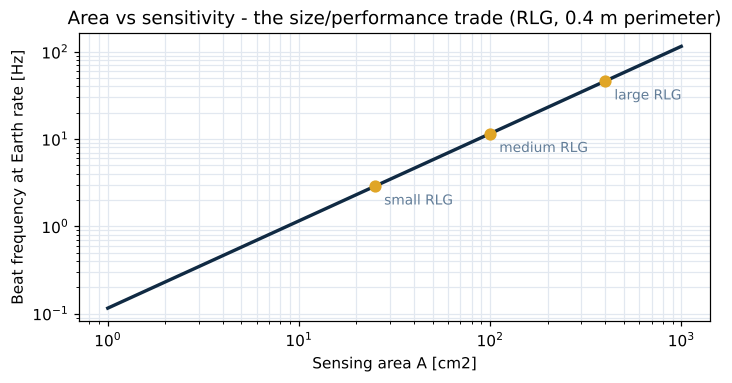

In [5]:
# [Exercise 2-2] How big is the Sagnac signal? Why gyros resist miniaturisation.
Omega_earth = OME            # 7.292e-5 rad/s = 15.04 deg/h
lam = 633e-9                 # He-Ne wavelength [m]

rows = []
for name, kind, R, L in [("Small RLG (5 cm side)",   "RLG", 0.05/2, 4*0.05),
                         ("Medium RLG (10 cm side)", "RLG", 0.10/2, 4*0.10),
                         ("FOG (8 cm coil, 500 m fibre)", "FOG", 0.08/2, 500.0)]:
    A  = np.pi*R**2 if kind == "FOG" else (2*R)**2
    dL = 4*A*Omega_earth/C_LIGHT                                   # path difference [m]
    if kind == "RLG":
        readout, unit = 4*A*Omega_earth/(L*lam), "beat freq [Hz]"
    else:
        readout, unit = 2*np.pi*L*(2*R)*Omega_earth/(lam*C_LIGHT)*1e6, "phase [urad]"
    rows.append([name, kind, A*1e4, dL*1e15, unit, readout])

df = pd.DataFrame(rows, columns=["Configuration", "Type", "Sensing area A [cm2]",
                                 "Path difference dL [fm] (1e-15 m)", "Quantity read", "Magnitude"])
show(df.round(3), "== Signal level when sensing Earth rotation (15 deg/h) ==")

print("\n-> The path difference itself is 2-10 fm, the diameter of an atomic nucleus.")
print("   It can never be read as a 'length'.")
print("-> An RLG converts it to a beat FREQUENCY, a FOG to an optical PHASE.")
print("-> The signal scales with the sensing area A: miniaturisation costs sensitivity,")
print("   which is the physical reason MEMS gyros plateau far below navigation grade.")

A_cm2  = np.logspace(0, 3, 200)
dnu_15 = 4*(A_cm2*1e-4)*Omega_earth/(0.4*lam)
fig, ax = plt.subplots(figsize=(7.4, 3.4))
ax.loglog(A_cm2, dnu_15, color=NAVY, lw=2.2)
for A0, lab in [(25, "small RLG"), (100, "medium RLG"), (400, "large RLG")]:
    y0 = 4*(A0*1e-4)*Omega_earth/(0.4*lam)
    ax.plot(A0, y0, "o", color=AMBER, ms=7, zorder=3)
    ax.annotate(lab, (A0, y0), textcoords="offset points", xytext=(6, -12),
                fontsize=9, color=MUTED)
ax.set_xlabel("Sensing area A [cm2]"); ax.set_ylabel("Beat frequency at Earth rate [Hz]")
ax.set_title("Area vs sensitivity - the size/performance trade (RLG, 0.4 m perimeter)")
ax.grid(True, which="both", color="#E2E8F0")
plt.show()

## 2.5 자이로 기술의 진화: 부품 수가 곧 원가이자 신뢰성

- 부품 수 = 원가·조립공수·고장률·소형화 여지를 **동시에** 지배
- 40여 년간 부품 수 약 40배 감소 → 성능뿐 아니라 **산업구조 자체의 변화**

> **소형 발사체가 열린 배경**
> - 고성능 관성센서 = 전통적으로 수억 원대의 수출통제 품목
> - 진동식·MEMS 자이로 + GNSS 결합 → 진입장벽 하락
> - 결과: 현재의 소형 발사체 스타트업 확산

> **성능–비용의 교환은 여전히 유효**
> - 부유식·정전부유식(ESG), 반구공진(HRG): 최고 성능 영역 유지 (바이어스 안정도 0.0001 °/h 수준)
> - MEMS: 성능이 두세 자릿수 낮음
> - → **'싸진 센서' ≠ '충분한 센서'**

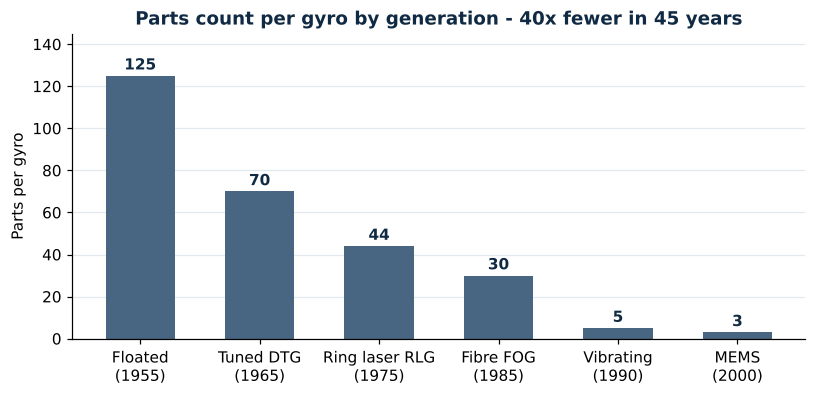

Floated -> MEMS: 125 -> 3 parts (42x fewer)


In [6]:
# [Exercise 2-3] Number of parts per gyro, by generation
gyro = pd.DataFrame({
    "Generation": ["Floated\n(1955)", "Tuned DTG\n(1965)", "Ring laser RLG\n(1975)",
                   "Fibre FOG\n(1985)", "Vibrating\n(1990)", "MEMS\n(2000)"],
    "Parts": [125, 70, 44, 30, 5, 3],
})
fig, ax = plt.subplots(figsize=(8.6, 3.6))
bars = ax.bar(gyro["Generation"], gyro["Parts"], color=STEEL, width=0.58)
for b, v in zip(bars, gyro["Parts"]):
    ax.text(b.get_x()+b.get_width()/2, v+3, str(v), ha="center", fontsize=10,
            fontweight="bold", color=NAVY)
ax.set_ylim(0, 145); ax.set_ylabel("Parts per gyro")
ax.set_title("Parts count per gyro by generation - 40x fewer in 45 years",
             color=NAVY, fontweight="bold")
ax.grid(axis="y", color="#E2E8F0"); ax.set_axisbelow(True)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
plt.show()

print(f"Floated -> MEMS: {gyro['Parts'].iloc[0]} -> {gyro['Parts'].iloc[-1]} parts "
      f"({gyro['Parts'].iloc[0]/gyro['Parts'].iloc[-1]:.0f}x fewer)")

## 2.6 짐벌식과 스트랩다운식

- 쟁점: **기계로 안정화할 것인가, 계산으로 안정화할 것인가**

| 구분 | 짐벌식 (Stable Platform) | 스트랩다운식 (Analytic Platform) |
|---|---|---|
| 구조 | 센서를 짐벌 위에 탑재, 항법좌표계에 상시 정렬 | 센서를 기체에 직접 고정, 짐벌을 **소프트웨어로 대체** |
| 핵심 계산 | 가속도계 출력을 그대로 적분 | 자이로로 좌표변환행렬 갱신 후 가속도 변환 |
| 크기·무게 | 대형 / 중량 (Saturn V 플랫폼 51 kg) | 소형 / 경량 |
| 충격·진동 | 기계부로 인해 취약 | 강함 (가동부 없음) |
| 장점 | 자체 교정(self-calibration) 가능, 절대성능 우수 | 경량·저비용, 이중화 용이 |
| **부담이 옮겨간 곳** | 정밀 기계가공, 서보 | **고속 연산, 수치적분 정확도** |

### 발사체별 채택 현황

| 짐벌식 · FRIG | 짐벌식 · DTG | 스트랩다운 · DTG | 스트랩다운 · RLG | 스트랩다운 · FOG |
|---|---|---|---|---|
| Saturn V, Atlas-Centaur, Ariane 1~4, Zenit, Proton, H-I, CZ-4 | Space Shuttle | Delta II, Taurus, Pegasus, PSLV, N-II, **나로호(KSLV-I)** | Atlas 5, Delta 4, Minotaur, Ariane 5, Vega, H-II/IIA, SLS | M-V, Falcon 1·9, CZ-8, **누리호(KSLV-II)** |

> - 1970년대까지 대형 발사체 = 짐벌식
> - 광학 자이로 등장 이후 신규 발사체 = 사실상 전량 스트랩다운으로 이행
> - 누리호: 국산 광섬유 자이로(KFG-1200) 기반 스트랩다운 채택

## 2.7 항법 기준좌표계와 기계화 방정식

- 쟁점: 어느 좌표계에서 적분하는가 → 방정식의 형태가 달라짐

| 좌표계 | 정의 | 특징 |
|---|---|---|
| **ECI (관성좌표계)** | 지구 중심, 항성 기준 비회전 | 가장 단순: 자세 = 자이로 측정치 직접 적분, 속도 = 비력 + 중력. **발사체 상승 구간의 표준** |
| ECEF (지구고정좌표계) | 지구 중심, 지구와 함께 자전 | 코리올리 항 $-2\boldsymbol{\omega}\times\mathbf{v}$·원심력 포함. 지상 낙하점·비행안전 판단에 편리 |
| LVLH (국지수평좌표계) | 기체 위치의 지역 수평면 기준 | 위도·경도·고도 직접 산출. 항공기·재진입체에 적합, 극지 특이점 존재 |

### ECI 기계화 (스트랩다운)

$$\dot{C}_b^i = C_b^i\, \Omega_{ib}^b \qquad (\Omega \text{는 자이로 각속도의 반대칭 행렬})$$
$$\dot{\mathbf{v}}^i = C_b^i\, \mathbf{a}^b + \mathbf{g}^i \qquad (\text{기체좌표 비력을 관성좌표로 변환 후 중력 가산})$$
$$\dot{\mathbf{r}}^i = \mathbf{v}^i$$

## 2.8 자세는 어떻게 표현하는가

| 표현법 | 파라미터 | 특이점 | 특징 | 용도 |
|---|---|---|---|---|
| 오일러각 | 3 | 2번째 회전각 ±90°에서 발생 | 미분방정식에 삼각함수 포함, 가속도 변환 시 방향코사인으로 재변환 필요 | 사람이 읽는 출력(피치·요·롤) |
| 방향코사인행렬 (DCM) | 9 | 없음 | 가속도 변환식에 직접 사용 가능. 9개 성분에 6개 직교 구속조건 → 중복 큼 | 좌표변환 연산 |
| **쿼터니언** | **4** | **없음** | 미분방정식 형태가 DCM과 유사, 파라미터는 절반 이하. 정규화만 유지하면 수치적으로 안정 | **자세 적분의 실제 구현** |

**오일러의 주회전 정리**
- 강체의 임의 자세 변화 = 하나의 주축 $\hat{e}$ 둘레로 하나의 주각 $\Phi$만큼 회전한 것으로 표현 가능
- 쿼터니언 = 이 $(\hat{e}, \Phi)$를 4개의 정규화된 성분으로 옮긴 것

> **특이점이 실제 문제가 된 사례**
> - Saturn V: 3축 짐벌 플랫폼, 요각 ±90°에서 짐벌락 → 중간 짐벌 ±45° 제한
> - Space Shuttle: 4축 짐벌 채택의 이유
> - 스트랩다운 + 쿼터니언: 제약 자체를 제거

After 200 s:  altitude =   188.3 km,  inertial speed =  3122.0 m/s,  body-axis tilt = 47.5 deg
Quaternion norm error = 0.00e+00  (stays ~1e-12 or below when normalised)
-> Altitude and speed are recovered from gyro + accelerometer output ONLY.
   Accuracy depends entirely on (i) initial attitude q0, (ii) sensor errors, (iii) the gravity model.


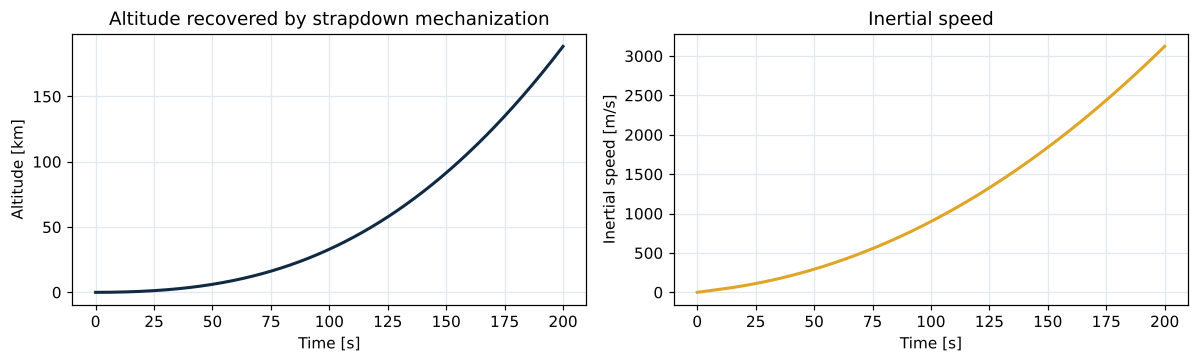

In [7]:
# [Exercise 2-4] Implement strapdown mechanization (quaternion + ECI velocity/position)
#   Build a simulated ascent, then recover the trajectory from gyro/accelerometer output only.

def quat_mult(q, p):
    w1, x1, y1, z1 = q; w2, x2, y2, z2 = p
    return np.array([w1*w2-x1*x2-y1*y2-z1*z2,
                     w1*x2+x1*w2+y1*z2-z1*y2,
                     w1*y2-x1*z2+y1*w2+z1*x2,
                     w1*z2+x1*y2-y1*x2+z1*w2])

def quat_to_dcm(q):
    w, x, y, z = q/np.linalg.norm(q)
    return np.array([[1-2*(y*y+z*z), 2*(x*y-w*z),   2*(x*z+w*y)],
                     [2*(x*y+w*z),   1-2*(x*x+z*z), 2*(y*z-w*x)],
                     [2*(x*z-w*y),   2*(y*z+w*x),   1-2*(x*x+y*y)]])

def strapdown(omega_b, f_b, dt, q0, v0, r0, gravity=True):
    # Strapdown INS mechanization in ECI, first-order integration.
    # omega_b[N,3]: gyro rates [rad/s];  f_b[N,3]: accelerometer specific force [m/s2]
    N = len(omega_b)
    q = q0.copy(); v = v0.copy(); r = r0.copy()
    R, V, Q = np.zeros((N, 3)), np.zeros((N, 3)), np.zeros((N, 4))
    for k in range(N):
        w = omega_b[k]; wn = np.linalg.norm(w)                  # (1) attitude update
        if wn > 1e-12:
            dq = np.concatenate([[np.cos(wn*dt/2)], np.sin(wn*dt/2)*w/wn])
        else:
            dq = np.array([1.0, 0, 0, 0])
        q = quat_mult(q, dq); q /= np.linalg.norm(q)
        Cbi = quat_to_dcm(q)                                    # (2) velocity update
        a_i = Cbi @ f_b[k]
        if gravity:
            rn = np.linalg.norm(r)
            a_i = a_i - MU * r / rn**3
        v = v + a_i*dt
        r = r + v*dt                                            # (3) position update
        R[k], V[k], Q[k] = r, v, q
    return R, V, Q

# --- simulated flight: vertical rise, then a constant pitch-over rate ---
dt, T_end = 0.01, 200.0
t = np.arange(0, T_end, dt); N = len(t)
pitch_rate = np.where(t < 10, 0.0, np.radians(0.25))            # 0.25 deg/s after 10 s
f_mag = np.where(t < 10, 1.4*g0, 1.4*g0 + 0.012*g0*(t-10))      # acceleration grows as mass burns off

omega_b = np.zeros((N, 3)); omega_b[:, 1] = pitch_rate           # body-y (pitch) rate
f_b = np.zeros((N, 3));     f_b[:, 0] = f_mag                    # thrust along body-x

q0 = np.array([1.0, 0.0, 0.0, 0.0])                              # body axis along local vertical (ECI +X)
r0 = np.array([RE, 0.0, 0.0]); v0 = np.zeros(3)
R, V, Q = strapdown(omega_b, f_b, dt, q0, v0, r0)

alt  = np.linalg.norm(R, axis=1) - RE
spd  = np.linalg.norm(V, axis=1)
tilt = np.degrees(np.cumsum(pitch_rate)*dt)
print(f"After {T_end:.0f} s:  altitude = {alt[-1]/1e3:7.1f} km,  inertial speed = {spd[-1]:7.1f} m/s,"
      f"  body-axis tilt = {tilt[-1]:.1f} deg")
print(f"Quaternion norm error = {abs(np.linalg.norm(Q[-1])-1):.2e}  (stays ~1e-12 or below when normalised)")
print("-> Altitude and speed are recovered from gyro + accelerometer output ONLY.")
print("   Accuracy depends entirely on (i) initial attitude q0, (ii) sensor errors, (iii) the gravity model.")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(t, alt/1e3, color=NAVY, lw=2)
axes[0].set_xlabel("Time [s]"); axes[0].set_ylabel("Altitude [km]")
axes[0].set_title("Altitude recovered by strapdown mechanization")
axes[1].plot(t, spd, color=AMBER, lw=2)
axes[1].set_xlabel("Time [s]"); axes[1].set_ylabel("Inertial speed [m/s]")
axes[1].set_title("Inertial speed")
for a in axes: a.grid(color="#E2E8F0"); a.set_axisbelow(True)
plt.tight_layout(); plt.show()

## 2.9 관성센서의 오차원(誤差源)

- 쟁점: 무엇이 **반복 가능한** 오차이고, 무엇이 그렇지 않은가

| 오차원 | 내용 |
|---|---|
| **바이어스 (Bias)** | 입력 0에서도 잔존하는 출력. 자이로 °/h, 가속도계 µg·mg 단위. **항법오차의 지배적 원인** |
| 스케일 팩터 (Scale Factor) | 참 입력에 비례해 증가하는 오차. 대추력 구간 등 입력이 큰 시점에서 영향 증대 |
| 비선형성·비대칭 | 입출력 관계의 직선 이탈, +/− 방향 기울기 차이 |
| 축 비정렬 (Misalignment) | 센서 감지축과 설계 기준축 간 어긋난 각도. µrad 단위 관리 |
| 잡음 (Noise) | 백색잡음·양자화잡음·플리커잡음 등 확률적 성분. **교정으로 제거 불가** |

$$\delta\boldsymbol{\omega} = \mathbf{B} + [\,SF,\ MA\,]\cdot\boldsymbol{\omega} + \boldsymbol{\eta}$$

> **반복 가능성이 기준선**
> - 반복 가능(repeatable) 오차 → 교정(calibration)으로 모델링·보상 가능
> - 반복 불가 성분 = **바이어스 불안정도 + 잡음** → 실제 항법 성능의 한계 결정

### Allan 분산 도표 읽기
- 평균화 시간 $\tau$에 대한 표준편차를 로그–로그로 도시 → **기울기별로 오차 성분 분리**

| 기울기 | 오차 성분 |
|---|---|
| $-1$ | 양자화잡음 |
| $-1/2$ | **각도 랜덤워크 (ARW)** |
| $0$ | **바이어스 불안정도** |
| $+1/2$ | 각속도 랜덤워크 |
| $+1$ | 각속도 램프 |

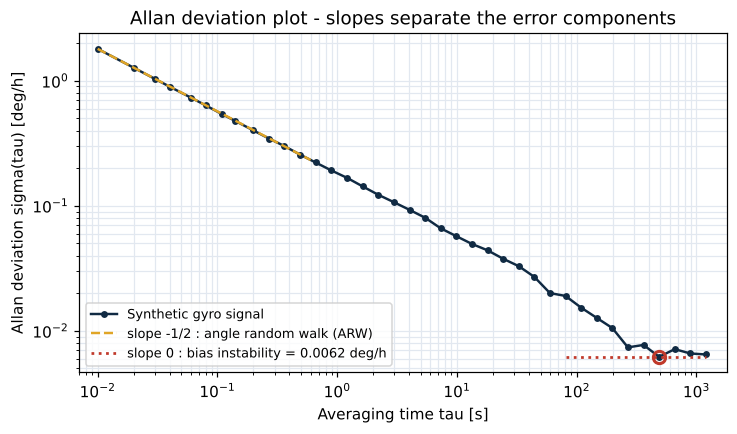

Plot minimum (bias instability) = 0.0062 deg/h  at tau = 488 s
-> This floor cannot be removed by calibration. Navigation specs are written against it.


In [8]:
# [Exercise 2-5] Compute the Allan deviation ourselves
#   Synthesise a gyro signal = white noise (ARW) + bias instability + rate ramp,
#   then see where each component shows up on the Allan plot.

rng = np.random.default_rng(7)
fs, dur = 100.0, 3600.0*3            # 100 Hz, 3 hours
n = int(fs*dur); dt_s = 1/fs

ARW   = 0.003                        # [deg/sqrt(h)]  angle random walk
B_ins = 0.01                         # [deg/h]        target bias instability
ramp  = 0.002                        # [deg/h/h]      rate ramp

wn = rng.normal(0, ARW*60/np.sqrt(dt_s), n)         # white noise in deg/h
bi = np.cumsum(rng.normal(0, 1, n))                 # random-walk proxy for flicker noise
bi = B_ins * bi/np.std(bi) * 0.8
rp = ramp * (np.arange(n)*dt_s/3600.0)
omega = wn + bi + rp                                # [deg/h]

def allan_dev(x, dt_s):
    N = len(x)
    ms = np.unique(np.logspace(0, np.log10(N//9), 40).astype(int))
    taus, ad = [], []
    for m in ms:
        k = N//m
        if k < 3: continue
        y = x[:k*m].reshape(k, m).mean(axis=1)       # cluster averages
        d = np.diff(y)
        taus.append(m*dt_s); ad.append(np.sqrt(0.5*np.mean(d**2)))
    return np.array(taus), np.array(ad)

tau, ad = allan_dev(omega, dt_s)
i0 = np.argmin(ad)
fig, ax = plt.subplots(figsize=(7.6, 4.0))
ax.loglog(tau, ad, "o-", color=NAVY, ms=3.5, lw=1.6, label="Synthetic gyro signal")
tt = np.logspace(np.log10(tau[0]), np.log10(tau[0]*60), 20)
ax.loglog(tt, ad[0]*(tt/tau[0])**-0.5, "--", color=AMBER, lw=1.6,
          label="slope -1/2 : angle random walk (ARW)")
ax.hlines(ad[i0], tau[max(i0-6, 0)], tau[-1], color="#C0392B", ls=":", lw=1.8,
          label=f"slope 0 : bias instability = {ad[i0]:.4f} deg/h")
ax.plot(tau[i0], ad[i0], "o", color="#C0392B", ms=8, mfc="none", mew=2)
ax.set_xlim(tau[0]*0.7, tau[-1]*1.5)
ax.set_xlabel("Averaging time tau [s]"); ax.set_ylabel("Allan deviation sigma(tau) [deg/h]")
ax.set_title("Allan deviation plot - slopes separate the error components")
ax.grid(True, which="both", color="#E2E8F0"); ax.legend(fontsize=8.5, loc="lower left")
plt.show()

print(f"Plot minimum (bias instability) = {ad[i0]:.4f} deg/h  at tau = {tau[i0]:.0f} s")
print("-> This floor cannot be removed by calibration. Navigation specs are written against it.")

## 2.10 관성항법장치의 성능 등급

- 등급 = 기술 분류이자 **수출통제의 분류**

| 등급 | 위치 성능 | 자이로 바이어스 | 가속도계 바이어스 | 자이로 기술 | 주요 적용 |
|---|---|---|---|---|---|
| 전략급 (Strategic) | 1 nmi / 24h | < 0.005 °/h | < 30 µg | ESG, RLG, FOG | ICBM, SLBM, 전략 자산 |
| **항법급 (Navigation)** | **1 nmi / h** | **0.01 °/h** | **50 µg** | RLG, FOG | **우주발사체**, 여객기 |
| 전술급 (Tactical) | > 10 nmi / h | 0.1 ~ 1 °/h | 1 mg | RLG, FOG | 전술 유도무기, 소형 발사체 |
| AHRS급 | — | 1 ~ 10 °/h | 1 mg | RLG, FOG, MEMS, 코리올리 | 자세방위 기준장치 |
| 제어급 (Control) | — | 10 ~ 1000 °/h | 10 mg | 코리올리 (MEMS) | 자세제어 보조, 상용 기기 |

> **발사체가 항법급이면 충분한 이유**
> - 발사체의 순수 관성비행 = 길어야 15~20분
> - 24시간 항행하는 잠수함과 달리 **오차 누적 시간이 짧음**
> - → 전략급 불필요, 항법급으로 요구 정확도 충족

> **정책적 함의: 이중용도의 정면**
> - 항법급 이상 관성센서 = MTCR 부속서·각국 수출통제 목록의 대표 통제 품목
> - 발사체 GNC 국산화 = '있으면 좋은 것'이 아닌 **'없으면 개발이 멈추는 것'**

## 2.11 자이로 바이어스는 어떻게 위치오차로 자라는가

- 적분 구조가 만드는 $t,\ t^2,\ t^3$ 성장 = **항법 성능 요구의 근거**

$$\delta\theta = \delta\omega_B\, t, \qquad
  \delta V = \tfrac{1}{2}\, g\, \delta\omega_B\, t^2, \qquad
  \delta p = \tfrac{1}{6}\, g\, \delta\omega_B\, t^3$$

- 메커니즘: 자세오차 발생 → 중력벡터가 수평 성분으로 누설($g\,\delta\theta$) → **가짜 수평가속도** 발생 → 재적분

실용 환산
- $\delta V \approx 0.0855\ \mathrm{(m/s)}\,/\,\mathrm{(°/h)}\,/\,\mathrm{min^2}$
- $\delta p \approx 1.71\ \mathrm{m}\,/\,\mathrm{(°/h)}\,/\,\mathrm{min^3}$

Rule-of-thumb check:  dV = 0.0856 (m/s)/(deg/h)/min^2    dp = 1.712 m/(deg/h)/min^3
== Error after 15 min (900 s) of pure inertial flight ==
   Nuri INGU spec: attitude 0.1 deg, velocity 3.0 m/s, position 1.5 km
 Gyro bias [deg/h]  Attitude err [deg]  Velocity err [m/s]  Position err [km]           Grade
             0.005              0.0012              0.0963             0.0289       Strategic
             0.010              0.0025              0.1926             0.0578      Navigation
             0.020              0.0050              0.3851             0.1155      Navigation
             0.050              0.0125              0.9628             0.2888 Tactical (edge)
             0.100              0.0250              1.9255             0.5777        Tactical
             1.000              0.2500             19.2553             5.7766            AHRS


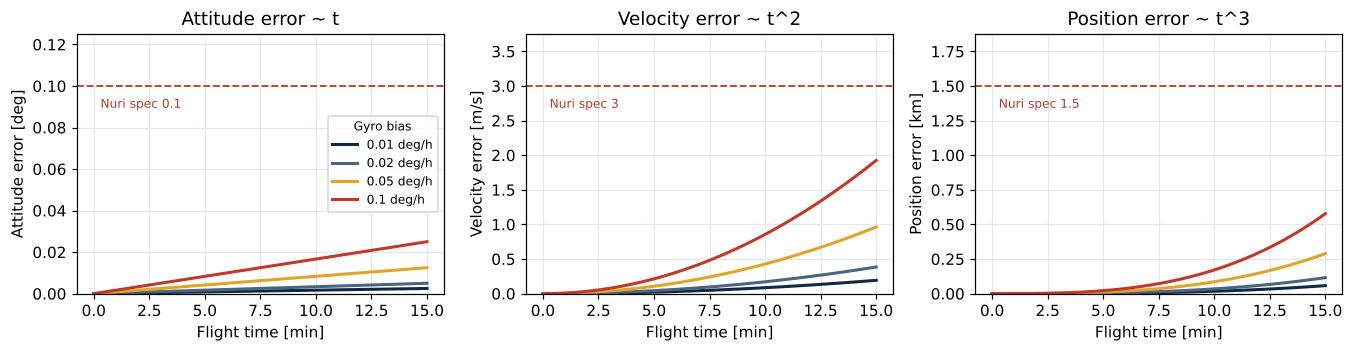


-> After 15 min, 0.01 deg/h gives about 58 m and 0.10 deg/h about 578 m of position error.
-> One sensor grade can decide whether the payload reaches orbit.

[Caution] These formulas assume a static, level platform. In flight, thrust acceleration,
          frame transformation and alignment error also act. Use them for order-of-magnitude
          intuition when setting requirements, not as a flight prediction.


In [9]:
# [Exercise 2-6] How a gyro bias grows into attitude, velocity and position error
def err_growth(bias_dph, t_min):
    # gyro bias [deg/h] -> attitude / velocity / position error after t [min]
    b = np.radians(bias_dph/3600.0)        # [rad/s]
    t = t_min*60.0
    dtheta = b*t                            # [rad]
    dV     = 0.5*g0*b*t**2                  # [m/s]
    dp     = (1/6)*g0*b*t**3                # [m]
    return np.degrees(dtheta), dV, dp

_, dV1, dp1 = err_growth(1.0, 1.0)
print(f"Rule-of-thumb check:  dV = {dV1:.4f} (m/s)/(deg/h)/min^2    dp = {dp1:.3f} m/(deg/h)/min^3")

rows = []
for b in [0.005, 0.01, 0.02, 0.05, 0.10, 1.0]:
    th, dv, dpv = err_growth(b, 15.0)
    rows.append([b, th, dv, dpv/1e3])
df = pd.DataFrame(rows, columns=["Gyro bias [deg/h]", "Attitude err [deg]",
                                 "Velocity err [m/s]", "Position err [km]"])
df["Grade"] = ["Strategic", "Navigation", "Navigation", "Tactical (edge)", "Tactical", "AHRS"]
show(df.round(4), "== Error after 15 min (900 s) of pure inertial flight ==\n"
                  "   Nuri INGU spec: attitude 0.1 deg, velocity 3.0 m/s, position 1.5 km")

tm = np.linspace(0, 15, 200)
fig, axes = plt.subplots(1, 3, figsize=(12.4, 3.3))
for b, c in zip([0.01, 0.02, 0.05, 0.10], PALETTE):
    th, dv, dpv = err_growth(b, tm)
    axes[0].plot(tm, th,      color=c, lw=2, label=f"{b:g} deg/h")
    axes[1].plot(tm, dv,      color=c, lw=2)
    axes[2].plot(tm, dpv/1e3, color=c, lw=2)
for ax, ttl, yl, spec in zip(axes,
        ["Attitude error ~ t", "Velocity error ~ t^2", "Position error ~ t^3"],
        ["Attitude error [deg]", "Velocity error [m/s]", "Position error [km]"], [0.1, 3.0, 1.5]):
    ax.axhline(spec, color="#C0392B", ls="--", lw=1.2)
    ax.set_ylim(0, spec*1.25)
    ax.text(0.3, spec*0.94, f"Nuri spec {spec:g}", fontsize=8, color="#C0392B", va="top")
    ax.set_xlabel("Flight time [min]"); ax.set_ylabel(yl); ax.set_title(ttl)
    ax.grid(color="#E2E8F0"); ax.set_axisbelow(True)
axes[0].legend(title="Gyro bias", fontsize=8, title_fontsize=8)
plt.tight_layout(); plt.show()

print("\n-> After 15 min, 0.01 deg/h gives about %.0f m and 0.10 deg/h about %.0f m of position error."
      % (err_growth(0.01, 15)[2], err_growth(0.10, 15)[2]))
print("-> One sensor grade can decide whether the payload reaches orbit.")
print("\n[Caution] These formulas assume a static, level platform. In flight, thrust acceleration,")
print("          frame transformation and alignment error also act. Use them for order-of-magnitude")
print("          intuition when setting requirements, not as a flight prediction.")

## 2.12 교정(Calibration)과 초기정렬(Alignment)

- **발사 전에 이미 절반은 결정됨**

### ① 교정 — 반복 가능한 오차의 표(모델)화

| 방식 | 내용 |
|---|---|
| **직접법 (Direct)** | 정밀 회전대에서 알려진 각속도 입력(**회전시험, rate test**) + 중력벡터에 대해 6~24개 자세 설정(**다위치시험, multi-position test**) → 계수를 직접 비교·추정 |
| **간접법 (Indirect)** | 각 축 180° 회전 전후의 속도·자세 오차로부터 계수 역추정 <br>- 장점: 시간 단축, 회전대 설치오차에 둔감, 정밀 각속도 모드 미사용으로 장비 수명에 유리 <br>- 단점: 항법 연산·데이터 처리 복잡 |

### ② 초기정렬 — 기준좌표계 대비 초기 자세 확정

| 단계 | 원리 | 산출물 |
|---|---|---|
| **개략정렬 (Coarse)** | 정지 상태 평균 가속도계 출력 = **중력벡터**, 자이로 출력 = **지구자전 각속도** 지시 <br>→ 두 기지 벡터를 기체좌표 관측값과 대조하여 방향코사인행렬을 해석적으로 계산 | 초기 DCM (개략) |
| **정밀정렬 (Fine)** | 확장칼만필터로 상태 추정 <br>정지 상태에서 참값이 0인 **수평 속도오차** $(\delta V_n, \delta V_e)$를 관측량으로 사용하여 자세 보정 | 정밀 초기자세 + 센서 바이어스 추정치 |

> **방위각 정렬의 한계**
> - 지구자전 각속도 = **15 °/h에 불과**
> - 자이로컴퍼싱만으로 방위각 정렬 시 센서 바이어스가 이보다 훨씬 작아야 함
> - → 발사체는 통상 발사대에서 **광학 정렬(optical alignment)** 로 방위각을 별도 주입
> - 누리호 INGU 방위각 정렬 요구: **0.025°(3σ)**

In [10]:
# [Exercise 2-7] Limits of gyrocompassing: bias -> azimuth error
#   At rest, the horizontal part of Earth rate (Omega*cos(lat)) points north.
#   A gyro bias b gives an azimuth error  d_psi ~ b / (Omega*cos(lat)).

lat = 34.43                                   # Naro Space Center latitude [deg]
Om_dph = np.degrees(OME)*3600                 # Earth rate [deg/h]
Om_h   = Om_dph*np.cos(np.radians(lat))       # horizontal component [deg/h]
print(f"Earth rate = {Om_dph:.3f} deg/h,  horizontal component at {lat} deg N = {Om_h:.3f} deg/h")

rows = []
for b, grade in [(0.005, "Strategic"), (0.01, "Navigation"), (0.1, "Tactical"), (1.0, "AHRS")]:
    dpsi = np.degrees(np.arcsin(np.clip(b/Om_h, -1, 1)))
    rows.append([grade, b, dpsi, "OK" if dpsi < 0.025 else "NO (optical alignment needed)"])
df = pd.DataFrame(rows, columns=["Grade", "Gyro bias [deg/h]", "Azimuth error [deg]",
                                 "Meets Nuri 0.025 deg?"])
show(df.round(4), "== Can azimuth be set by gyrocompassing alone? ==")
print("\n-> Even a navigation-grade 0.01 deg/h gyro gives %.3f deg, above the 0.025 deg requirement." %
      np.degrees(np.arcsin(0.01/Om_h)))
print("-> That is why launchers inject azimuth by OPTICAL alignment (theodolite) on the pad.")

# --- coarse alignment (TRIAD) implemented directly ---
def coarse_align(f_b, w_b, lat_deg):
    # estimate the body->NED DCM from static IMU output (f_b: specific force, w_b: rate)
    phi = np.radians(lat_deg)
    g_n = np.array([0, 0, -g0])                                  # gravity in NED (down positive)
    w_n = OME*np.array([np.cos(phi), 0, -np.sin(phi)])           # Earth rate in NED
    def triad(a, b):
        e1 = a/np.linalg.norm(a)
        e2 = np.cross(a, b); e2 /= np.linalg.norm(e2)
        return np.column_stack([e1, e2, np.cross(e1, e2)])
    Mn = triad(-g_n, w_n)            # reference frame
    Mb = triad(f_b,  w_b)            # body-frame observation (static: f_b = -g_b)
    return Mn @ Mb.T                 # C_b^n

def euler_to_dcm(r, p, y):
    cr, sr, cp, sp, cy, sy = np.cos(r), np.sin(r), np.cos(p), np.sin(p), np.cos(y), np.sin(y)
    return np.array([[cp*cy, sr*sp*cy-cr*sy, cr*sp*cy+sr*sy],
                     [cp*sy, sr*sp*sy+cr*cy, cr*sp*sy-sr*cy],
                     [-sp,   sr*cp,          cr*cp]])

C_true = euler_to_dcm(*np.radians([2.0, -3.0, 35.0]))           # roll 2, pitch -3, yaw 35 deg
phi = np.radians(lat)
f_n = np.array([0, 0, g0]); w_n = OME*np.array([np.cos(phi), 0, -np.sin(phi)])
f_b_true, w_b_true = C_true.T @ f_n, C_true.T @ w_n

print("\n== Coarse alignment accuracy (TRIAD) vs gyro bias ==")
for b_dph in [0.0, 0.01, 0.1]:
    bias  = np.radians(b_dph/3600)*np.array([1, 1, 1])/np.sqrt(3)
    C_est = coarse_align(f_b_true, w_b_true + bias, lat)
    dC    = C_est.T @ C_true
    ang   = np.degrees(np.arccos(np.clip((np.trace(dC)-1)/2, -1, 1)))
    print(f"  gyro bias {b_dph:5.3f} deg/h  ->  attitude estimate error {ang:7.4f} deg")

Earth rate = 15.041 deg/h,  horizontal component at 34.43 deg N = 12.406 deg/h
== Can azimuth be set by gyrocompassing alone? ==
     Grade  Gyro bias [deg/h]  Azimuth error [deg]         Meets Nuri 0.025 deg?
 Strategic              0.005               0.0231                            OK
Navigation              0.010               0.0462 NO (optical alignment needed)
  Tactical              0.100               0.4618 NO (optical alignment needed)
      AHRS              1.000               4.6234 NO (optical alignment needed)

-> Even a navigation-grade 0.01 deg/h gyro gives 0.046 deg, above the 0.025 deg requirement.
-> That is why launchers inject azimuth by OPTICAL alignment (theodolite) on the pad.

== Coarse alignment accuracy (TRIAD) vs gyro bias ==
  gyro bias 0.000 deg/h  ->  attitude estimate error  0.0000 deg
  gyro bias 0.010 deg/h  ->  attitude estimate error  0.0355 deg
  gyro bias 0.100 deg/h  ->  attitude estimate error  0.3547 deg


## 2.13 위성항법 보강 관성항법 (GNSS-aided INS)

- 전통: 발사체 항법 = 순수 관성 (외부 신호 비의존이 최대 장점)
- 변화 요인
  - 고성능 센서의 고가·수출통제 부담
  - 저비용 소형 발사체의 확산
  - **재사용 발사체의 착륙 요구**
- → 중급 관성센서 + GNSS 결합이 표준적 대안으로 부상

| 결합 방식 | 사용하는 측정치 | 장점 | 단점 |
|---|---|---|---|
| **느슨한 결합 (Loosely)** | 수신기 출력(위치·속도·시각, PVT) | 구현 단순, 센서 호환성 우수 | 위성 4기 이상 확보 전제 |
| **강한 결합 (Tightly)** | 의사거리·의사거리율·반송파 위상 등 **원시 측정치** | 위성 4기 미만에서도 동작 | 수신기 내부 접근 필요 |
| **심결합 (Deeply)** | 수신기 누적 상관기 출력 $(I, Q)$ | 성능·강건성 최우수 | 최고 복잡도, 통합 설계 필요 |

**개루프 vs 폐루프 융합**
- 개루프: 관성 해에 보정량을 가산하여 사용
- 폐루프: 관성 적분 자체를 융합 추정치로 주기적 **재설정**
  - 상태가 원점 근처에 상주 → 선형화 오차·수치 문제 감소

> **재사용 발사체의 요구**
> - 1단 회수 → 지상 착륙점에 **미터급** 접근 필요
> - 관성 + GNSS만으로 부족 → 전파고도계 등 추가 항법 센서 요구
> - 항법 문제가 상승 구간을 넘어 **하강·착륙 구간**으로 확장

After 900 s:  pure INS position error =      195.8 m
              INS/GNSS coupled        =        0.6 m
Bias estimate: true 50.0 ug -> estimated 47.1 ug


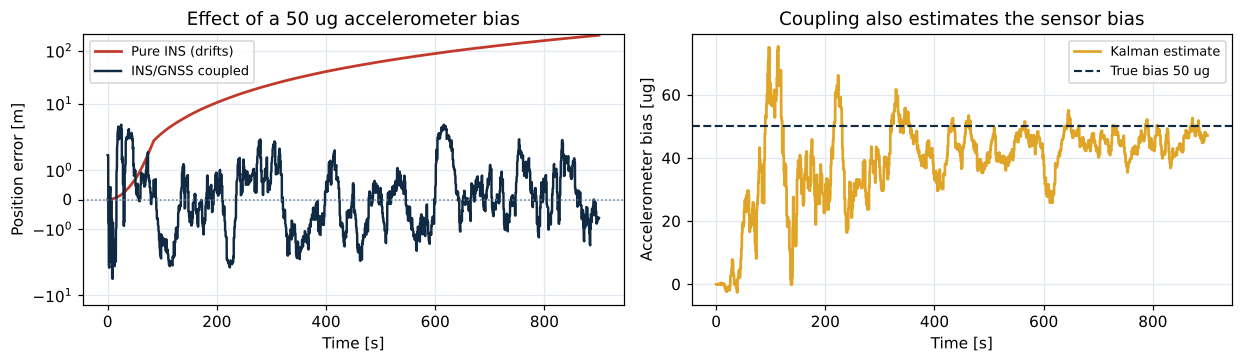


-> The point of coupling is not to 'fix the position' but to ESTIMATE and remove the error source.
   That is why performance holds for a while even after GNSS is lost (coasting).


In [11]:
# [Exercise 2-8] Loosely coupled INS/GNSS - a 1-D Kalman filter removes the drift
#   INS: smooth and low-noise, but drifts with bias.  GNSS: noisy, but unbiased.

dt_k, T_k = 0.01, 900.0                   # 100 Hz, 900 s (the Nuri navigation-spec duration)
n = int(T_k/dt_k); t_k = np.arange(n)*dt_k
rng = np.random.default_rng(11)

acc_bias  = 50e-6*g0                      # 50 ug accelerometer bias (navigation grade)
acc_noise = 50e-6*g0*10
true_a = np.zeros(n)
meas_a = true_a + acc_bias + rng.normal(0, acc_noise, n)

# --- pure INS (integration only) ---
v_ins = np.cumsum(meas_a)*dt_k
p_ins = np.cumsum(v_ins)*dt_k

# --- INS/GNSS Kalman filter (states: position, velocity, accel bias) ---
F = np.array([[1, dt_k, -0.5*dt_k**2],
              [0, 1,    -dt_k],
              [0, 0,     1]])
B = np.array([0.5*dt_k**2, dt_k, 0.0])
Q = np.diag([1e-8, 1e-6, 1e-12])
H = np.array([[1.0, 0, 0]])
gnss_sig, gnss_hz = 5.0, 1.0              # GNSS position noise 5 m at 1 Hz
R = np.array([[gnss_sig**2]])
x = np.zeros(3); P = np.diag([10.0**2, 1.0**2, (100e-6*g0)**2])
p_kf, b_kf = np.zeros(n), np.zeros(n)
step = int(1/gnss_hz/dt_k)
for k in range(n):
    x = F @ x + B*meas_a[k]; P = F @ P @ F.T + Q
    if k % step == 0:
        z = np.array([0.0 + rng.normal(0, gnss_sig)])
        y = z - H @ x
        S = H @ P @ H.T + R
        K = P @ H.T @ np.linalg.inv(S)
        x = x + (K @ y).ravel(); P = (np.eye(3) - K @ H) @ P
    p_kf[k], b_kf[k] = x[0], x[2]

print(f"After 900 s:  pure INS position error = {abs(p_ins[-1]):10.1f} m")
print(f"              INS/GNSS coupled        = {abs(p_kf[-1]):10.1f} m")
print(f"Bias estimate: true {acc_bias/g0*1e6:.1f} ug -> estimated {b_kf[-1]/g0*1e6:.1f} ug")

fig, axes = plt.subplots(1, 2, figsize=(11.4, 3.4))
axes[0].plot(t_k, p_ins, color="#C0392B", lw=1.8, label="Pure INS (drifts)")
axes[0].plot(t_k, p_kf,  color=NAVY, lw=1.6, label="INS/GNSS coupled")
axes[0].axhline(0, color=MUTED, ls=":", lw=1)
axes[0].set_xlabel("Time [s]"); axes[0].set_ylabel("Position error [m]"); axes[0].set_yscale("symlog")
axes[0].set_title("Effect of a 50 ug accelerometer bias"); axes[0].legend(fontsize=8.5)
axes[1].plot(t_k, b_kf/g0*1e6, color=AMBER, lw=1.8, label="Kalman estimate")
axes[1].axhline(acc_bias/g0*1e6, color=NAVY, ls="--", lw=1.4, label="True bias 50 ug")
axes[1].set_xlabel("Time [s]"); axes[1].set_ylabel("Accelerometer bias [ug]")
axes[1].set_title("Coupling also estimates the sensor bias"); axes[1].legend(fontsize=8.5)
for a in axes: a.grid(color="#E2E8F0"); a.set_axisbelow(True)
plt.tight_layout(); plt.show()

print("\n-> The point of coupling is not to 'fix the position' but to ESTIMATE and remove the error source.")
print("   That is why performance holds for a while even after GNSS is lost (coasting).")

---
# 제3부 · 유도 (Guidance)

> 비행 단계 · 오차 예산 · 하중경감 · 최적조향법칙 · 폐루프 알고리즘

## 3.1 이륙에서 궤도투입까지: 유도의 관점에서 본 비행 단계

| # | 단계 | 유도의 역할 |
|---|---|---|
| 1 | 수직 상승 (Vertical Rise) | 발사대 이탈·탑 회피. 자세 유지만 수행, 궤적 최적화 없음 |
| 2 | 방위각 롤 (Roll Program) | 목표 궤도경사각에 맞는 발사 방위각으로 기체 회전 |
| 3 | 피치 프로그램 · 중력선회 | 사전 설계된 자세 프로파일로 받음각 최소화하며 수평으로 전환 |
| **4** | **최대동압 · 제트기류 통과** | **구조하중 최대 구간. 하중경감(load-relief)이 지배** |
| 5 | 단분리 · 페어링 분리 | 동압이 충분히 낮아진 뒤 페어링 분리로 질량 감소 |
| **6** | **폐루프 명시적 유도** | **진공 구간. 목표 궤도 조건 만족 + 추진제 소모 최소화** |
| 7 | 엔진 정지 · 위성 분리 | 유도가 계산한 잔여시간 $t_{go}$에 따라 정지 명령 발행 |

> - **대기권 내(1~5단계)**: 목표 = 구조하중 최소화
> - **대기권 외(6~7단계)**: 목표 = 궤도투입 오차 최소화
> - 하나의 유도법칙이 두 목표를 동시에 다루지 않음 = 발사체 유도 설계의 기본 구조

## 3.2 유도는 무엇을 흡수하는가: 3σ 성능 산포

- 이상 로켓방정식이 다루지 않는 **'산포'** 의 크기를 수치로 확인

== dV error budget of an example 3-stage launcher ==
      Error source +/-3 sigma [%]  Stage 1 dV [m/s]  Stage 2 dV [m/s]  Stage 3 dV [m/s]
        Inert mass          +0.30               1.6               2.6               4.7
       LOX loading  -0.63 ~ -1.29              18.1              17.9              60.7
      Fuel loading  +0.62 ~ +0.74               8.9              11.4              31.6
Mixture ratio (MR)  +1.00 ~ +2.00              18.9              36.7              88.6
            Thrust  -2.40 ~ +2.40              40.4              11.6               7.4
  Specific impulse          -0.80              24.8              26.5              38.2
              Drag         +15.00              16.1               0.0               0.0

Per-stage RSS : Stage 1:   57.2 m/s   Stage 2:   51.4 m/s   Stage 3:  118.6 m/s
Total RSS     : 141.4 m/s

-> A total RSS of 141 m/s is 1.52% of the 9,300 m/s total dV,
   yet the allowed insertion error is far smaller. Closed-loop guidance e

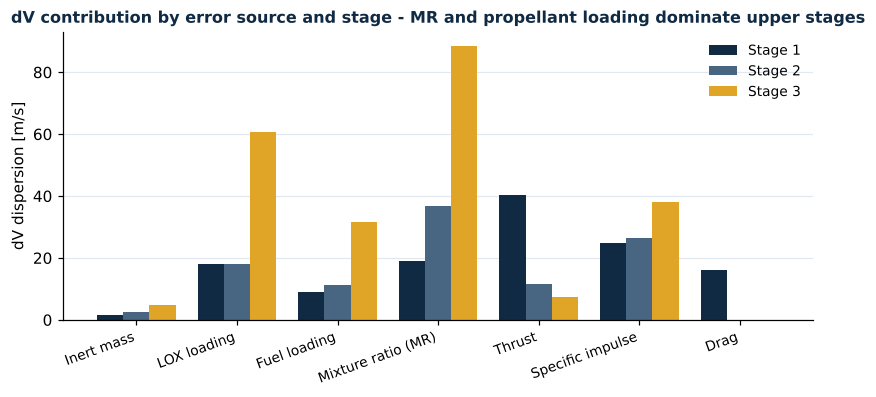

In [12]:
# [Exercise 3-1] dV error budget of a 3-stage launcher and RSS combination
budget = pd.DataFrame({
    "Error source": ["Inert mass", "LOX loading", "Fuel loading", "Mixture ratio (MR)",
                     "Thrust", "Specific impulse", "Drag"],
    "+/-3 sigma [%]": ["+0.30", "-0.63 ~ -1.29", "+0.62 ~ +0.74", "+1.00 ~ +2.00",
                       "-2.40 ~ +2.40", "-0.80", "+15.00"],
    "Stage 1 dV [m/s]": [1.6, 18.1,  8.9, 18.9, 40.4, 24.8, 16.1],
    "Stage 2 dV [m/s]": [2.6, 17.9, 11.4, 36.7, 11.6, 26.5, 0.0],
    "Stage 3 dV [m/s]": [4.7, 60.7, 31.6, 88.6,  7.4, 38.2, 0.0],
})
rss = lambda v: float(np.sqrt(np.sum(np.asarray(v, float)**2)))
stage_cols = ["Stage 1 dV [m/s]", "Stage 2 dV [m/s]", "Stage 3 dV [m/s]"]
stage_rss  = {c: rss(budget[c]) for c in stage_cols}
total_rss  = rss(list(stage_rss.values()))
show(budget, "== dV error budget of an example 3-stage launcher ==")
print("\nPer-stage RSS :", "   ".join(f"Stage {i+1}: {v:6.1f} m/s" for i, v in enumerate(stage_rss.values())))
print(f"Total RSS     : {total_rss:.1f} m/s")

dv_total = 9300.0
print(f"\n-> A total RSS of {total_rss:.0f} m/s is {total_rss/dv_total*100:.2f}% of the {dv_total:,.0f} m/s total dV,")
print("   yet the allowed insertion error is far smaller. Closed-loop guidance exists to bridge that gap.")

fig, ax = plt.subplots(figsize=(8.8, 3.4))
idx = np.arange(len(budget)); w = 0.26
for i, (c, col) in enumerate(zip(stage_cols, [NAVY, STEEL, AMBER])):
    ax.bar(idx + (i-1)*w, budget[c], width=w, color=col, label=f"Stage {i+1}")
ax.set_xticks(idx)
ax.set_xticklabels(budget["Error source"], rotation=20, ha="right", fontsize=9)
ax.set_ylabel("dV dispersion [m/s]"); ax.legend(fontsize=9, frameon=False)
ax.set_title("dV contribution by error source and stage - MR and propellant loading dominate upper stages",
             color=NAVY, fontweight="bold", fontsize=10.5)
ax.grid(axis="y", color="#E2E8F0"); ax.set_axisbelow(True)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
plt.show()

## 3.3 속도오차 몇 m/s가 만드는 결과

- 궤도역학은 작은 오차에 관대하지 않음

### ① 궤도 진입 실패의 문턱
- 근지점이 해수면까지 내려가는 데 필요한 속도 부족분(deorbit 조건)
  - 200 km 원궤도: 약 **60 m/s**
  - 700 km 원궤도: 약 **198 m/s**
- 60 m/s = 총 속도증분의 **0.6%에 불과**

### ② 궤도 형상 오차

$$da = \frac{2a^2}{\mu}\,V\,dV, \qquad \Delta h \approx \frac{4a^2}{\mu}\,V_p\,\Delta V_p$$

- $\pm 3$ m/s = 총 속도증분 9,300 m/s의 **0.03%**
- 그 0.03%가 고도 10 km의 궤도 오차로 증폭

| | 크기 | 총 ΔV 대비 | 의미 |
|---|---|---|---|
| 성능 산포 (3σ RSS) | ≈ 141 m/s | 1.5 % | 유도 부재 시 그대로 궤도오차로 전환 |
| 궤도 진입 실패 문턱 | ≈ 60 m/s | 0.6 % | **산포보다 작음** — 개루프만으로는 실패 가능 |
| 요구 투입 정확도 | ≈ 3 m/s | 0.03 % | 폐루프 유도 없이는 도달 불가 |

== Orbital-mechanics consequences of velocity error ==
 Circular alt [km]  Circular speed [m/s]  Failure threshold dV [m/s]  Share of total dV [%]  da @ 3 m/s [km]  dh_apogee @ 3 m/s [km]
               200               7784.26                       60.31                   0.65             5.07                   10.14
               300               7725.76                       89.27                   0.96             5.19                   10.37
               500               7612.61                      144.95                   1.56             5.42                   10.84
               700               7504.29                      197.79                   2.13             5.66                   11.32


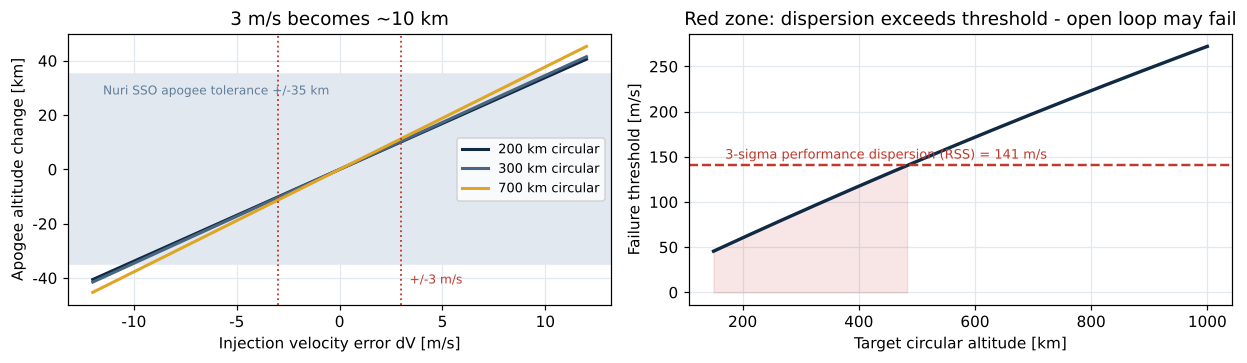

-> Below about 487 km, the 3-sigma performance dispersion (141 m/s) exceeds the failure threshold.
   For low orbits, closed-loop guidance is therefore essential.


In [13]:
# [Exercise 3-2] Velocity error -> orbit error, and the "failure to reach orbit" threshold

def deorbit_margin(h_circ_km):
    # velocity shortfall [m/s] that drops perigee to the surface (r = RE)
    r = RE + h_circ_km*1e3
    v_circ = np.sqrt(MU/r)
    a_t = (r + RE)/2
    v_apo = np.sqrt(MU*(2/r - 1/a_t))
    return v_circ - v_apo, v_circ

def orbit_sensitivity(h_km, dV):
    # semi-major-axis and apogee change caused by velocity error dV on a circular orbit
    r = RE + h_km*1e3; a = r; V = np.sqrt(MU/r)
    da   = 2*a**2/MU * V * dV
    dh_a = 4*a**2/MU * V * dV
    return da, dh_a

rows = []
for h in [200, 300, 500, 700]:
    dvm, vc = deorbit_margin(h)
    da, dha = orbit_sensitivity(h, 3.0)
    rows.append([h, vc, dvm, dvm/9300*100, da/1e3, dha/1e3])
df = pd.DataFrame(rows, columns=["Circular alt [km]", "Circular speed [m/s]", "Failure threshold dV [m/s]",
                                 "Share of total dV [%]", "da @ 3 m/s [km]", "dh_apogee @ 3 m/s [km]"])
show(df.round(2), "== Orbital-mechanics consequences of velocity error ==")

fig, axes = plt.subplots(1, 2, figsize=(11.4, 3.4))
dv = np.linspace(-12, 12, 200)
for h, c in zip([200, 300, 700], [NAVY, STEEL, AMBER]):
    _, dha = orbit_sensitivity(h, dv)
    axes[0].plot(dv, dha/1e3, color=c, lw=2, label=f"{h} km circular")
axes[0].axhspan(-35, 35, color="#E2E8F0", zorder=0)
axes[0].text(-11.5, 31, "Nuri SSO apogee tolerance +/-35 km", fontsize=8, color=MUTED, va="top")
axes[0].axvline(3, color="#C0392B", ls=":", lw=1.2); axes[0].axvline(-3, color="#C0392B", ls=":", lw=1.2)
axes[0].text(3.4, -42, "+/-3 m/s", fontsize=8, color="#C0392B")
axes[0].set_xlabel("Injection velocity error dV [m/s]"); axes[0].set_ylabel("Apogee altitude change [km]")
axes[0].set_title("3 m/s becomes ~10 km"); axes[0].legend(fontsize=8.5)

hs = np.linspace(150, 1000, 200)
margins = np.array([deorbit_margin(h)[0] for h in hs])
axes[1].plot(hs, margins, color=NAVY, lw=2.2)
axes[1].axhline(141.3, color="#C0392B", ls="--", lw=1.6)
axes[1].text(170, 148, "3-sigma performance dispersion (RSS) = 141 m/s", fontsize=8.5, color="#C0392B")
axes[1].fill_between(hs, 0, margins, where=margins < 141.3, color="#C0392B", alpha=0.12)
axes[1].set_xlabel("Target circular altitude [km]"); axes[1].set_ylabel("Failure threshold [m/s]")
axes[1].set_title("Red zone: dispersion exceeds threshold - open loop may fail")
for a in axes: a.grid(color="#E2E8F0"); a.set_axisbelow(True)
plt.tight_layout(); plt.show()

h_cross = hs[np.argmin(np.abs(margins-141.3))]
print(f"-> Below about {h_cross:.0f} km, the 3-sigma performance dispersion (141 m/s) exceeds the failure threshold.")
print("   For low orbits, closed-loop guidance is therefore essential.")

## 3.4 개루프 유도와 폐루프 유도

| | 개루프 유도 (Open-Loop) | 폐루프 유도 (Closed-Loop) |
|---|---|---|
| 동작 | 자세 명령을 비행 전 설계, **시간의 함수**로 탑재 | 항법의 현재 위치·속도를 되먹임, 자세 명령·엔진 정지 시각을 **실시간 재계산** |
| 설계 목표 | 고동압 구간 받음각 최소화 | 종말 조건(목표 궤도) 만족 + 추진제 소모 최소화 |
| 산포 흡수 | 불가 | **가능 (유일한 수단)** |
| 장점 | 예측 가능, 하중 관리에 유리 | 성능 산포·외란에 강건 |

### 폐루프 유도의 두 갈래

| 구분 | 동작 방식 | 특징 | 대표 기법 |
|---|---|---|---|
| **음함수 (Implicit)** | 미리 정한 **기준궤적**으로 복귀하도록 오차 감소 | 기준궤적 이탈분만 수정 — 최적성 미보장 | Delta Guidance, Q-Guidance |
| **양함수 (Explicit)** | 현재 상태에서 목표까지 **새로운 경로**를 매 주기 재생성 | 기준궤적 불필요, 큰 이탈에도 대응 — 연산 부담 큼 | IGM, PEG, LTG, 최적유도 |

> - 실제 발사체 = 두 방식을 **시간축에서 분리**하여 사용
> - 대기권 구간: 개루프 (하중경감 포함) / 진공 구간: 양함수 폐루프
> - 현재의 표준 구성

## 3.5 대기권 구간의 지배 변수: 바람

- 쟁점: 이 구간만 '최적 궤적'을 포기하는 이유

$$F_N = \tfrac{1}{2}\rho V^2 S C_{N\alpha}\,\alpha \;\propto\; Q\,\alpha,
\qquad \text{굽힘모멘트} \;\propto\; Q\alpha \;\text{및 TVC 편향각}\ \delta$$

- 기체 대기속도 = 지구기준 속도 − **바람벡터** → **바람이 곧 받음각을 생성**
- 동압 $Q$ 최대 고도(약 10~13 km)에서 제트기류 조우 시 $Q\alpha$ 급증
- → 구조 굽힘하중과 TVC 요구 편향각이 동시에 상승

| 기법 | 내용 |
|---|---|
| **하중경감 유도 (Load-Relief)** | 자세각 대신 **받음각(또는 횡가속도)** 감소 방향으로 명령 수정. 궤적 최적성 일부 포기, 구조 여유 확보 |
| **계절풍 바이어스 (Wind Biasing)** | 계절별 평균 바람 프로파일을 피치 프로그램에 사전 반영. 99% $Q\alpha$ 게이지 기준 **15~19% 저감**, TVC 최대 요구각 **9% 저감** 보고 |
| **발사 당일 바람 운용 (Day-of-Launch)** | 발사 수 시간 전 기구(balloon) 실측 바람으로 자세 프로파일 재설계·탑재. $Q\alpha$ 기준 **50% 이상 저감** 가능 |

> **운용상의 함의**
> - 발사 당일 바람 반영 = 성능상 효과 최대
> - 절차: 발사 6시간 전부터 기구 상승 → 데이터 평가 → 궤적 재설계 → 하중 검증 → 성능 검증, 발사 1시간 이내 탑재값(I-load) 재장입
> - → **알고리즘이 아닌 발사 운용 조직·절차의 문제**
> - **발사장 운영 역량이 탑재중량으로 환산되는 대표 사례**

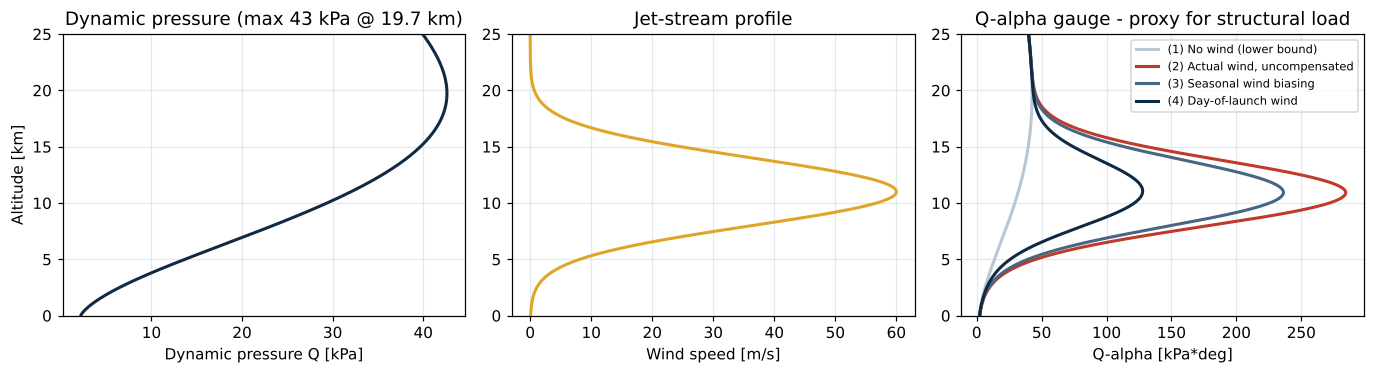

== Peak Q-alpha and reduction relative to (2) uncompensated ==
  (1) No wind (lower bound)        max Q-alpha =    42.6 kPa*deg   ( 85.0% reduction)  <- unattainable lower bound
  (2) Actual wind, uncompensated   max Q-alpha =   284.2 kPa*deg   (  0.0% reduction)
  (3) Seasonal wind biasing        max Q-alpha =   236.3 kPa*deg   ( 16.9% reduction)
  (4) Day-of-launch wind           max Q-alpha =   127.8 kPa*deg   ( 55.0% reduction)

-> Seasonal biasing ~17% and day-of-launch ~55%: the same order as reported in the literature
   (seasonal 15-19%, day-of-launch 50%+).
   Q-alpha reduction is structural margin, and structural margin converts into payload mass at design time.


In [14]:
# [Exercise 3-3] Q-alpha profile - how the jet stream drives structural load

def rho_isa(h):
    # simple exponential atmosphere density [kg/m3]
    return 1.225*np.exp(-h/8500.0)

h = np.linspace(0, 25e3, 400)
V = 60 + 420*(h/12e3)**1.25                    # airspeed vs altitude [m/s]
Q = 0.5*rho_isa(h)*V**2                        # dynamic pressure [Pa]

def wind(h, peak=60.0, h0=11e3, sig=3.0e3):
    # jet-stream wind profile, peak 60 m/s near 11 km
    return peak*np.exp(-0.5*((h-h0)/sig)**2)

W_nom = wind(h, 60.0)
alpha_nowind   = np.radians(1.0)*np.ones_like(h)                 # design alpha margin
alpha_wind     = alpha_nowind + W_nom/V                          # extra alpha from wind
alpha_seasonal = alpha_nowind + (W_nom - wind(h, 60*0.19))/V     # 19% compensated by seasonal mean wind
alpha_dol      = alpha_nowind + (W_nom - wind(h, 60*0.62))/V     # 62% compensated by day-of-launch wind

Qa = {"(1) No wind (lower bound)":    Q*np.degrees(alpha_nowind),
      "(2) Actual wind, uncompensated": Q*np.degrees(alpha_wind),
      "(3) Seasonal wind biasing":    Q*np.degrees(alpha_seasonal),
      "(4) Day-of-launch wind":       Q*np.degrees(alpha_dol)}

fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.5))
axes[0].plot(Q/1e3, h/1e3, color=NAVY, lw=2); axes[0].set_xlabel("Dynamic pressure Q [kPa]")
axes[0].set_ylabel("Altitude [km]")
axes[0].set_title(f"Dynamic pressure (max {Q.max()/1e3:.0f} kPa @ {h[np.argmax(Q)]/1e3:.1f} km)")
axes[1].plot(W_nom, h/1e3, color=AMBER, lw=2); axes[1].set_xlabel("Wind speed [m/s]")
axes[1].set_title("Jet-stream profile")
for (k, v), c in zip(Qa.items(), ["#B9C6D3", "#C0392B", STEEL, NAVY]):
    axes[2].plot(v/1e3, h/1e3, color=c, lw=2, label=k)
axes[2].set_xlabel("Q-alpha [kPa*deg]"); axes[2].set_title("Q-alpha gauge - proxy for structural load")
axes[2].legend(fontsize=7.5)
for a in axes: a.grid(color="#E2E8F0"); a.set_axisbelow(True); a.set_ylim(0, 25)
plt.tight_layout(); plt.show()

base = Qa["(2) Actual wind, uncompensated"].max()
print("== Peak Q-alpha and reduction relative to (2) uncompensated ==")
for k, v in Qa.items():
    tag = "  <- unattainable lower bound" if k.startswith("(1)") else ""
    print(f"  {k:<32s} max Q-alpha = {v.max()/1e3:7.1f} kPa*deg   ({(1-v.max()/base)*100:5.1f}% reduction){tag}")
print("\n-> Seasonal biasing ~17% and day-of-launch ~55%: the same order as reported in the literature")
print("   (seasonal 15-19%, day-of-launch 50%+).")
print("   Q-alpha reduction is structural margin, and structural margin converts into payload mass at design time.")

## 3.6 최적 조향법칙은 어디에서 오는가

- 평면지구 궤도투입 문제에서 유도되는 **이중선형 탄젠트(bilinear tangent)** 법칙

### ① 문제 설정
$$\min J = t_f \quad (\text{연소시간 최소} = \text{추진제 최소})$$
$$\dot{x}=v_x,\quad \dot{y}=v_y,\quad \dot{v}_x=\frac{F}{m}\cos\alpha,\quad \dot{v}_y=\frac{F}{m}\sin\alpha - g$$
$$\text{종말조건:}\quad y_f=h_c,\quad v_{xf}=v_c,\quad v_{yf}=0$$

### ② 최적성 조건
해밀토니안 $H = L + \boldsymbol{\lambda}^T \mathbf{f}$ 에 오일러–라그랑주 식 적용
$$\dot\lambda_1=\dot\lambda_2=0,\quad \dot\lambda_3=-\lambda_1,\quad \dot\lambda_4=-\lambda_2
\;\Rightarrow\; \lambda_3 = -c_1 t + c_3,\quad \lambda_4 = -c_2 t + c_4$$
그리고 $\partial H/\partial\alpha = 0$ 으로부터

### ③ 결과
$$\boxed{\ \tan\alpha = \frac{\lambda_4}{\lambda_3} = \frac{-c_2 t + c_4}{-c_1 t + c_3}\ }$$

- 최적 자세 명령의 **탄젠트 = 시간의 일차분수함수**
- = **이중선형 탄젠트 조향법칙**

### 두 번의 단순화 — 실제 알고리즘의 출처

**① 비행거리(down-range) 비구속**
- 횡방향 종말조건 없음 → $\lambda_1 = c_1 = 0$

$$\tan\alpha = a\,t + b \qquad (\textbf{선형 탄젠트 조향법칙})$$

- 궤도투입 문제는 대개 이 경우에 해당

**② 종말 속도벡터만 구속**
- $\tan\alpha = c_4/c_3 = \text{일정}$ → **추력 방향 고정**이 최적
- 상단 유도에서 자세 명령이 거의 선형으로 완만하게 변하는 이유
- IGM이 자세를 '초기값 + 일정 변화율'로 파라미터화할 수 있는 근거

> **교훈**
> - 실제 발사체: 매 주기 최적제어 문제를 풀지 않음
> - **최적해의 함수 형태를 사전에 파악 → 계수만 실시간으로 조정**
> - '온보드 최적화 없이 최적성을 얻는 법' = 발사체 유도 알고리즘 설계의 핵심 발상

== Three steering-law FORMS meeting the same terminal conditions ==
                                   Steering-law form  Burn time t_f [s]  Propellant [kg]  Terminal residual [max]  Extra vs optimal [kg]
        Linear tangent  (tan a = A t + B)  [optimal]            206.134        94232.621                      0.0                  0.000
Linear sine  (sin a = A t + B)  [Atlas-Centaur, H-I]            207.381        94802.613                      0.0                569.992
                         Linear angle  (a = A + B t)            208.455        95293.554                      0.0               1060.933

-> The form that uses the least propellant is 'Linear tangent' - as optimal-control theory predicts.
-> Linear sine costs 570 kg more; linear angle costs 1,061 kg more.
   1,000 kg of upper-stage propellant is several hundred kg of LEO payload: the choice of form IS performance.

[How to read] In the middle panel only the optimal law gives a smooth monotonic decrease.
  Linear sin

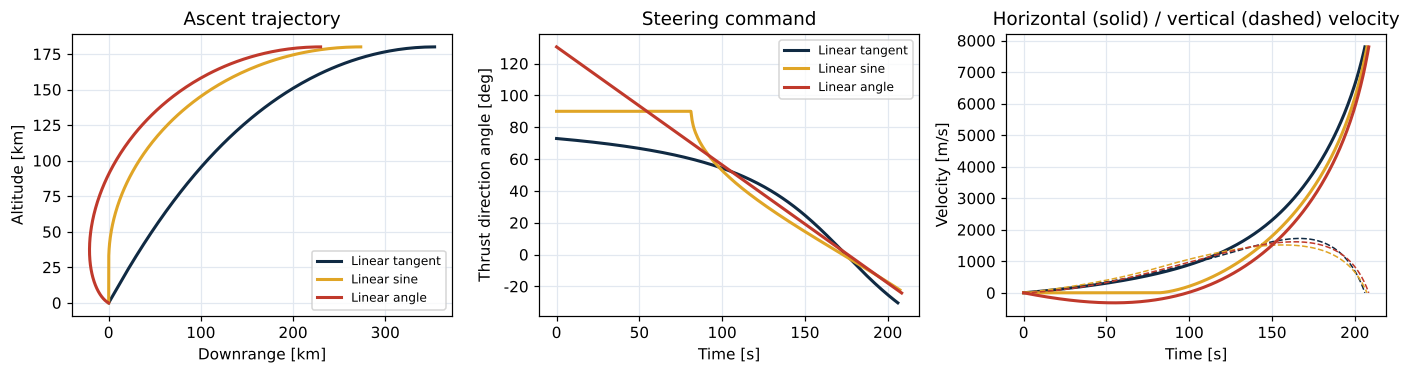

In [15]:
# [Exercise 3-4] Solve the linear-tangent steering law numerically and check optimality
#   Solve a flat-Earth ascent with three different steering-law FORMS and compare propellant.
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares

# --- upper-stage-like vehicle ---
Isp_s, m0_s, TW = 350.0, 100_000.0, 1.6
T_s   = TW*m0_s*g0
mdot  = T_s/(Isp_s*g0)
hc, vc = 180e3, 7800.0                   # terminal: 180 km altitude, 7800 m/s horizontal, 0 vertical speed
SC = np.array([1e4, 1e2, 1e2])           # residual scaling

def propagate(alpha_fn, tf):
    def rhs(t, s):
        _, _, vx, vy = s
        acc = T_s/(m0_s - mdot*t)
        a = alpha_fn(t)
        return [vx, vy, acc*np.cos(a), acc*np.sin(a) - g0]
    return solve_ivp(rhs, [0, tf], [0, 0, 0, 0], rtol=1e-10, atol=1e-8, dense_output=True)

def solve_family(fam, guess):
    def resid(p):
        s = propagate(fam(p), p[2]).y[:, -1]
        return np.array([s[1]-hc, s[2]-vc, s[3]])/SC
    r = least_squares(resid, guess, xtol=1e-14, ftol=1e-14)
    return r.x, np.max(np.abs(resid(r.x)*SC))

families = {
    "Linear tangent  (tan a = A t + B)  [optimal]":
        (lambda p: (lambda t: np.arctan(p[0]*t + p[1])), [-0.01, 1.0, 200.0]),
    "Linear sine  (sin a = A t + B)  [Atlas-Centaur, H-I]":
        (lambda p: (lambda t: np.arcsin(np.clip(p[0]*t + p[1], -1, 1))), [-0.006, 0.95, 206.0]),
    "Linear angle  (a = A + B t)":
        (lambda p: (lambda t: p[0] + p[1]*t), [1.27, -0.0085, 206.0]),
}
short = {k: k.split("  (")[0] for k in families}

res, sols = [], {}
for name, (fam, g_) in families.items():
    p, err = solve_family(fam, g_)
    sols[name] = (fam(p), p)
    res.append([name, p[2], mdot*p[2], err])

df = pd.DataFrame(res, columns=["Steering-law form", "Burn time t_f [s]",
                                "Propellant [kg]", "Terminal residual [max]"])
df["Extra vs optimal [kg]"] = df["Propellant [kg]"] - df["Propellant [kg]"].min()
show(df.round(3), "== Three steering-law FORMS meeting the same terminal conditions ==")

best = df.loc[df["Propellant [kg]"].idxmin(), "Steering-law form"].split("  (")[0]
print(f"\n-> The form that uses the least propellant is '{best}' - as optimal-control theory predicts.")
print(f"-> Linear sine costs {df['Extra vs optimal [kg]'].iloc[1]:,.0f} kg more; "
      f"linear angle costs {df['Extra vs optimal [kg]'].iloc[2]:,.0f} kg more.")
print("   1,000 kg of upper-stage propellant is several hundred kg of LEO payload: the choice of form IS performance.")
print("\n[How to read] In the middle panel only the optimal law gives a smooth monotonic decrease.")
print("  Linear sine saturates at 90 deg early (arcsin limit) and wastes thrust vertically;")
print("  linear angle demands a physically awkward attitude above 90 deg at the start.")

fig, axes = plt.subplots(1, 3, figsize=(12.8, 3.5))
for (name, (afn, p)), c in zip(sols.items(), [NAVY, AMBER, "#C0392B"]):
    sol = propagate(afn, p[2]); tt = np.linspace(0, p[2], 300); yy = sol.sol(tt)
    lbl = short[name]
    axes[0].plot(yy[0]/1e3, yy[1]/1e3, color=c, lw=2, label=lbl)
    axes[1].plot(tt, np.degrees([afn(x) for x in tt]), color=c, lw=2, label=lbl)
    axes[2].plot(tt, yy[2], color=c, lw=2); axes[2].plot(tt, yy[3], color=c, lw=1, ls="--")
axes[0].set_xlabel("Downrange [km]"); axes[0].set_ylabel("Altitude [km]"); axes[0].set_title("Ascent trajectory")
axes[0].legend(fontsize=8)
axes[1].set_xlabel("Time [s]"); axes[1].set_ylabel("Thrust direction angle [deg]")
axes[1].set_title("Steering command"); axes[1].legend(fontsize=8)
axes[2].set_xlabel("Time [s]"); axes[2].set_ylabel("Velocity [m/s]")
axes[2].set_title("Horizontal (solid) / vertical (dashed) velocity")
for a in axes: a.grid(color="#E2E8F0"); a.set_axisbelow(True)
plt.tight_layout(); plt.show()

## 3.7 실제 발사체의 명시적 폐루프 유도 방식

- 차이의 본질 = 같은 최적해를 **어떤 형태로 파라미터화했는가**

| 유도 방식 | 채택 발사체 | 파라미터화의 특징 | 장·단점 |
|---|---|---|---|
| 선형 사인 법칙 (Linear-Sine) | Atlas-Centaur, H-I, H-II | $\sin\theta$를 시간 일차식 + 중력·속도항의 조합으로 표현 | 해석적 형태 단순, 초기 발사체에 적합 / 정확도 한계 |
| **반복 유도 방식 (IGM)** | **Saturn I·V, 누리호(KSLV-II), CZ-8** | 최적 자세명령이 거의 선형이라는 성질 활용, $\theta$를 **(초기값, 변화율)** 로 파라미터화 | 반복 계산 불필요, 연산 부담 작음 / 강한 비선형 상황에서 근사 오차 |
| 동력 명시 유도 (PEG) | Space Shuttle, SLS | IGM 보완, 자세를 스칼라 각이 아닌 **벡터 명령**으로 파라미터화 | 해가 일반적 / 예측–수정(predictor–corrector) 반복 필요 |
| 선형 탄젠트 변형 (LTG) | H-IIA, Ariane-5 | 최적해에 더 근접한 형태로 파라미터화, 또는 경계조건 연립식 선형화 후 차분보정 | 최적성 높음 / 수렴성 관리·검증 부담 큼 |

> **누리호의 IGM 계열 채택 = 보수적이면서 합리적인 선택**
> - 반복 계산 없음 → 최악의 경우에도 **연산시간이 결정론적으로 보장**
> - → 비행소프트웨어 검증(V&V) 부담 대폭 경감
> - **유도 알고리즘 선택 = 성능뿐 아니라 '검증 가능성'의 문제**

## 3.8 폐루프 명시 유도 알고리즘의 계산 순서

### 다섯 개의 목표 변수, 다섯 개의 유도 변수

**목표 변수 (5개)**
- 위치·속도 벡터는 6개이나, 궤도투입에서는 비행거리(도달 지점)가 자유변수 → 실제 구속은 5개
- 고도(반경) · 총속도 · 비행경로각(또는 수직속도) · 궤도경사각 · 승교점 적경

**결정할 유도 변수 (5개)**
- 피치 자세와 그 변화율 (2)
- 요 자세와 그 변화율 (2)
- 궤도투입까지 남은 시간 $t_{go}$ (1)

> 미지수와 구속조건의 개수 일치 = 알고리즘 성립의 **구조적 조건**

| 단계 | 내용 | 수식 |
|---|---|---|
| **①** | 속도 조건을 만족하는 자세각 $\theta_{Gv}$ 산출 | 목표 속도벡터 − 현재 속도 − 중력 기여 = 소요 속도증분 $\Delta V_G$의 방향각: $\theta_{Gv} = \tan^{-1}(\Delta V_{Gy}/\Delta V_{Gx})$ |
| **②** | 남은 연소시간 $t_{go}$ 산출 | $\tau = V_{ex}/a_0$ 갱신 후 로켓방정식의 역함수 적용: $t_{go} = \tau\left(1 - e^{-\Delta V/V_{ex}}\right)$ |
| **③** | 위치 조건까지 만족하는 $\theta_{Gp}$와 변화율 산출 | 자세를 (초기 편차 + 일정 변화율)로 설정, 적분항 $L, J, S, Q$ 로 속도·위치 종말조건을 동시에 만족하는 두 계수를 연립으로 해결 |

> - 산출 명령을 최적제어 직접 해와 비교 시, 궤도요소 기준 차이는 사실상 무시 가능
>   (예: 고도 0.2 km, 속도 0.02 m/s, 경사각 0.000°)
> - **실시간으로 풀 수 없는 문제를 실시간으로 푸는 방법 = 근사의 승리**

In [16]:
# [Exercise 3-5] The heart of IGM - t_go and the integrals L, J, S, Q

def igm_terms(a0, Vex, tgo):
    # IGM integrals: L (velocity), J (velocity x time), S (position), Q (position x time)
    tau = Vex/a0                                   # acceleration time constant
    L = -Vex*np.log(1 - tgo/tau)                   # integral of a dt      = required velocity gain
    J = L*tau - Vex*tgo                            # integral of a t dt
    S = L*tgo - J                                  # double integral       = position contribution
    Q = J*tau - 0.5*Vex*tgo**2
    return L, J, S, Q, tau

def tgo_from_dv(a0, Vex, dV):
    # burn time needed to gain dV (inverse of the rocket equation)
    tau = Vex/a0
    return tau*(1 - np.exp(-dV/Vex))

Isp3, a0_3 = 325.0, 8.5
Vex = Isp3*g0
print(f"Stage-3 assumption: Isp = {Isp3:.0f} s -> Vex = {Vex:,.0f} m/s,  current acceleration a0 = {a0_3:.1f} m/s2")
print(f"                    acceleration time constant tau = Vex/a0 = {Vex/a0_3:,.1f} s\n")

rows = []
for dV in [500, 1000, 1500, 2000, 2500]:
    tgo = tgo_from_dv(a0_3, Vex, dV)
    L, J, S, Q, tau = igm_terms(a0_3, Vex, tgo)
    rows.append([dV, tgo, L, J/1e3, S/1e3, Q/1e6])
df = pd.DataFrame(rows, columns=["Required dV [m/s]", "t_go [s]", "L [m/s]", "J [km]", "S [km]", "Q [1e6 m*s]"])
show(df.round(2), "== t_go and integral terms vs required velocity gain ==")
print("\nCheck: L must equal the required dV ->", np.allclose(df['L [m/s]'], df['Required dV [m/s]'], rtol=1e-6))

print("\n== With a thrust dispersion: open loop vs closed loop ==")
dV_need = 2000.0
for dT in [-0.024, 0.0, +0.024]:                   # thrust +/-2.4% (3 sigma)
    a0p = a0_3*(1+dT)
    tgo_nom = tgo_from_dv(a0_3, Vex, dV_need)       # cutoff time fixed before flight
    tau_p   = Vex/a0p
    dV_ol   = -Vex*np.log(1 - tgo_nom/tau_p)        # open loop: fixed time -> dV varies
    tgo_cl  = tgo_from_dv(a0p, Vex, dV_need)        # closed loop: fixed dV -> time varies
    print(f"  thrust {dT*100:+5.1f}% | open loop: cutoff {tgo_nom:6.1f} s fixed -> dV {dV_ol:7.1f} m/s "
          f"(error {dV_ol-dV_need:+6.1f}) | closed loop: dV {dV_need:.0f} m/s -> cutoff {tgo_cl:6.1f} s "
          f"({tgo_cl-tgo_nom:+5.1f} s)")
print("\n-> Open loop fixes the TIME and leaves a velocity error; closed loop fixes the VELOCITY and moves the time.")
print("   Compare with the ~60 m/s failure threshold of Exercise 3-2 to see why closed loop is mandatory.")

Stage-3 assumption: Isp = 325 s -> Vex = 3,187 m/s,  current acceleration a0 = 8.5 m/s2
                    acceleration time constant tau = Vex/a0 = 375.0 s

== t_go and integral terms vs required velocity gain ==
 Required dV [m/s]  t_go [s]  L [m/s]  J [km]  S [km]  Q [1e6 m*s]
               500     54.44    500.0   13.97   13.25         0.51
              1000    100.98   1000.0   53.13   47.85         3.67
              1500    140.76   1500.0  113.82   97.32        11.10
              2000    174.76   2000.0  192.92  156.60        23.67
              2500    203.83   2500.0  287.76  221.82        41.69

Check: L must equal the required dV -> True

== With a thrust dispersion: open loop vs closed loop ==
  thrust  -2.4% | open loop: cutoff  174.8 s fixed -> dV  1933.9 m/s (error  -66.1) | closed loop: dV 2000 m/s -> cutoff  179.1 s ( +4.3 s)
  thrust  +0.0% | open loop: cutoff  174.8 s fixed -> dV  2000.0 m/s (error   +0.0) | closed loop: dV 2000 m/s -> cutoff  174.8 s ( +0.0 s)


---
# 제4부 · 시스템 사례

> Saturn V와 Space Shuttle에서 누리호까지 — 설계 선택과 비행 결과

## 4.1 짐벌 플랫폼 시대: Saturn V와 Space Shuttle

### Saturn V
- 벤딕스社 **ST-124-M 3축 짐벌 안정 플랫폼**, 무게 51 kg
- 플랫폼 온도 43 °C 안정화 → 센서 특성 고정
- 관성좌표계 → 기체좌표 변환: **피치→요→롤** 순서의 오일러각 사용
- 요각 ±90°에서 **짐벌락** 발생 → 중간 짐벌 ±45° 제한
- 방위각: **광학 세오돌라이트**로 정렬
- 유도: **IGM(반복 유도 방식)** — 현재 누리호까지 이어지는 계보

### Space Shuttle
- 싱어-키어폿社 KT-70, **4축 짐벌** — 짐벌락 제약을 구조로 해결
- 고정밀 관성항법장치(HAINS) **3중 이중화**, 1대당 27 kg
- IMU 고장검출·분리(FDI) 논리로 **다수결** 선정
- 유도: **PEG** — 자세를 벡터 명령으로 파라미터화, 예측–수정 반복
- **발사 당일 바람 운용(Day-of-Launch)** 절차 정립

> **두 사례의 교훈**
> - Saturn V: 짐벌락(기하학적 제약)을 **운용 제한**으로 우회
> - Shuttle: 축 추가, **하드웨어**로 해결
> - 스트랩다운 + 쿼터니언: 제약 자체를 **소프트웨어**로 소멸
> - 동일 문제를 세대별로 다른 층위(운용 → 하드웨어 → 소프트웨어)에서 해결 = 시스템 공학의 전형적 궤적

## 4.2 누리호(KSLV-II)의 항법유도 시스템

- 임무 요구 → 성능 규격 → 단별 설계로 이어지는 경로 추적

In [17]:
# [Exercise 4-1] Nuri (KSLV-II): mission requirement, INGU spec, per-stage guidance and control

mission = pd.DataFrame({
    "Item": ["Payload mass", "Perigee altitude", "Apogee altitude", "Inclination"],
    "SSO":  ["1,500 kg", "700 +/- 7 km",  "700 +/- 35 km", "98.2 +/- 0.1 deg"],
    "LEO":  ["2,600 kg", "300 +/- 3 km",  "300 +/- 20 km", "80.3 +/- 0.1 deg"],
})
show(mission, "== (1) Mission requirements ==")

ingu = pd.DataFrame({
    "Item": ["Alignment - azimuth", "Alignment - level", "Navigation - attitude",
             "Navigation - velocity", "Navigation - position"],
    "Spec (3 sigma)": ["0.025 deg", "0.014 deg", "0.1 deg", "3.0 m/s", "1.5 km"],
    "Note": ["optical alignment", "-", "over 900 s", "over 900 s", "over 900 s"],
})
show(ingu, "\n== (2) Inertial Navigation & Guidance Unit (INGU) performance spec ==")

stages = pd.DataFrame({
    "Stage / phase": ["Stage 1", "Stage 2", "Stage 3 (powered)", "Stage 3 (coast)"],
    "Engine cutoff": ["propellant depletion", "propellant depletion", "commanded by guidance", "-"],
    "Guidance": ["Load-relief w/ day-of-launch wind", "Nominal open loop", "Closed loop", "Nominal open loop"],
    "Attitude control": ["4-engine TVC, 3 axes", "1-engine TVC + turbine exhaust nozzle",
                         "1-engine TVC + RCS", "RCS, 3 axes"],
})
show(stages, "\n== (3) Guidance and control by stage ==")

print('''
== Hardware ==
  - Navigation, guidance and control integrated in a single unit; strapdown inertial navigation
  - Sensor block: 3 domestic fibre-optic gyros (KFG-1200) + 4 accelerometers
  - On-board computer: PowerPC 7410 450 MHz, MIL-STD-1553B and RS-422

>> Insertion accuracy = (1) navigation performance + (2) guidance accuracy + (3) residual-thrust modelling error.
   As the flight result shows, (3) was the dominant term.''')

need_bias = 3.0/(0.5*g0*(900.0)**2) * 3600 * (180/np.pi)
print(f"\n[Back-calculation] If gyro bias ALONE caused the 3.0 m/s velocity error over 900 s: bias <~ {need_bias:.3f} deg/h.")
print("  In reality alignment error, accelerometer bias, scale factor and misalignment add in RSS.")
print("  Splitting the budget evenly over n sources tightens each requirement by 1/sqrt(n):")
for n_src in [3, 5, 10]:
    print(f"    - {n_src:2d} sources -> gyro bias <~ {need_bias/np.sqrt(n_src):.4f} deg/h")
print("  Adding margin for ageing, temperature and launch vibration lands near the 'navigation grade' 0.01 deg/h.")
print("  The spec is not an arbitrary number - it is the result of error budgeting.")

== (1) Mission requirements ==
            Item              SSO              LEO
    Payload mass         1,500 kg         2,600 kg
Perigee altitude     700 +/- 7 km     300 +/- 3 km
 Apogee altitude    700 +/- 35 km    300 +/- 20 km
     Inclination 98.2 +/- 0.1 deg 80.3 +/- 0.1 deg

== (2) Inertial Navigation & Guidance Unit (INGU) performance spec ==
                 Item Spec (3 sigma)              Note
  Alignment - azimuth      0.025 deg optical alignment
    Alignment - level      0.014 deg                 -
Navigation - attitude        0.1 deg        over 900 s
Navigation - velocity        3.0 m/s        over 900 s
Navigation - position         1.5 km        over 900 s

== (3) Guidance and control by stage ==
    Stage / phase         Engine cutoff                          Guidance                      Attitude control
          Stage 1  propellant depletion Load-relief w/ day-of-launch wind                  4-engine TVC, 3 axes
          Stage 2  propellant depletion         

## 4.3 비행 전에 무엇으로 확신을 얻는가

- 누리호 항법유도장치의 **검증 체계** — 성능시험 · 환경시험 · 실환경 시험

| 단계 | 내용 |
|---|---|
| **정렬·정지항법 시험** | X·Y·Z축 각각 ±1 g가 되는 6개 자세에서 정렬오차, 자이로·가속도계 바이어스 추정치, 정지 상태 항법오차 성장을 반복 확인 |
| **환경 인증시험** | 진동(20 g rms) · 파이로 충격(SRS 3,000 g) · 고가속 · 열주기(−34 ~ +71 °C) · 열진공(1.33×10⁻² Pa) · EMC(MIL-STD-461F) <br>관성센서는 환경에 특히 민감 → **환경시험이 곧 성능시험** |
| **지상 주행 시험** | 기준 항법장치(SIGMA30) 동반 탑재, 차량 주행, 1,000초 기준 항법오차 비교 <br>자세 0.01° 이내, 속도 0.3 m/s 이내, 위치 0.12 km 이내 — 규격 대비 여유 확인 |
| **항공기 비행시험** | Cessna 208B 탑재, 2,400초 비행 <br>실제 기동·진동 환경에서 자세 0.06° 이내, 속도 0.4 m/s 이내, 위치 0.52 km 이내 확인 |

> - 검증의 계단: **정지 → 주행 → 비행 → 발사**
> - 단계마다 실환경 요소를 하나씩 추가
> - **참값을 알 수 있는 기준장치와의 비교 가능성**은 끝까지 유지
> - = 항법 검증의 기본 설계

## 4.4 누리호 2차 비행시험 결과 (2022. 6. 21)

- 항법 · 유도 · 잔류추력 — 오차를 **세 갈래로 분해**하여 해석

== (1) Navigation performance over 900 s, vs GNSS ==
                  Item  Result Unit  Spec (3 sigma)  Spec used [%]
Velocity difference dV    0.70  m/s             3.0           23.3
Altitude difference dh   -0.40   km             1.5           26.7
   Range difference dR    0.47   km             1.5           31.3
-> The inertial solution stayed within about 1/3 of spec for 900 s. Navigation met its requirement with margin.

== (2) Stage-3 engine cutoff state (time from T3) ==
                   Item  Nominal design  Guidance result  Difference
        Cutoff time [s]        526.4800         509.1300    -17.3500
          Radius R [km]       7078.1370        7078.1050     -0.0320
          Speed V [m/s]       7497.8370        7497.6910     -0.1460
Flight-path angle [deg]          0.0090           0.0256      0.0166
  RAAN difference [deg]          1.5436           1.5492      0.0056
      Inclination [deg]         98.1700          98.1470     -0.0230

== (3) Achieved orbit at sate

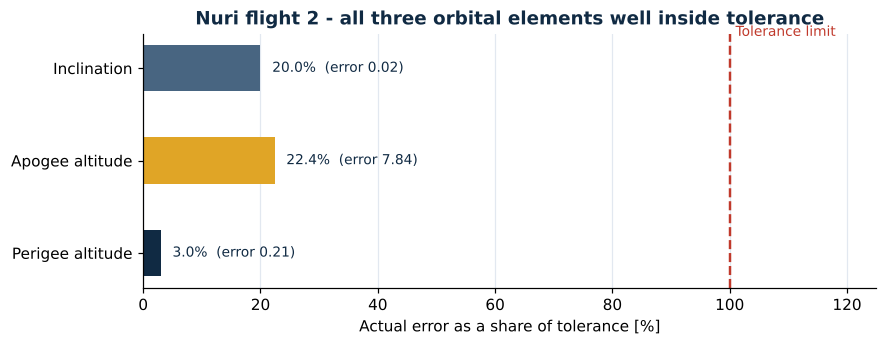

In [18]:
# [Exercise 4-2] Decomposing the Nuri 2nd flight test (21 June 2022) into three parts

nav = pd.DataFrame({
    "Item":   ["Velocity difference dV", "Altitude difference dh", "Range difference dR"],
    "Result": [0.7, -0.4, 0.47],
    "Unit":   ["m/s", "km", "km"],
    "Spec (3 sigma)": [3.0, 1.5, 1.5],
})
nav["Spec used [%]"] = (nav["Result"].abs()/nav["Spec (3 sigma)"]*100).round(1)
show(nav, "== (1) Navigation performance over 900 s, vs GNSS ==")
print("-> The inertial solution stayed within about 1/3 of spec for 900 s. Navigation met its requirement with margin.\n")

guid = pd.DataFrame({
    "Item": ["Cutoff time [s]", "Radius R [km]", "Speed V [m/s]", "Flight-path angle [deg]",
             "RAAN difference [deg]", "Inclination [deg]"],
    "Nominal design": [526.48, 7078.137, 7497.837, 0.0090, 1.5436, 98.1700],
    "Guidance result": [509.13, 7078.105, 7497.691, 0.0256, 1.5492, 98.1470],
})
guid["Difference"] = (guid["Guidance result"] - guid["Nominal design"]).round(4)
show(guid, "== (2) Stage-3 engine cutoff state (time from T3) ==")

orbit = pd.DataFrame({
    "Item": ["Perigee altitude [km]", "Apogee altitude [km]", "Inclination [deg]"],
    "Requirement": ["700 +/- 7", "700 +/- 35", "98.19 +/- 0.1"],
    "Tolerance": [7.0, 35.0, 0.1],
    "Result": [699.79, 707.84, 98.17],
    "Target": [700.0, 700.0, 98.19],
})
orbit["Error"] = (orbit["Result"] - orbit["Target"]).abs().round(3)
orbit["Share of tolerance [%]"] = (orbit["Error"]/orbit["Tolerance"]*100).round(1)
show(orbit, "\n== (3) Achieved orbit at satellite separation ==")

print('''
== How to read the result ==
  - Cutoff came 17.35 s earlier than nominal: real performance was better than nominal, and the
    closed-loop guidance absorbed that surplus exactly.
  - The error created by the guidance algorithm itself is ~0.03 km and ~0.15 m/s: negligible.
  - What remains - especially the 7.84 km apogee excess - comes mostly from the stage-3 RESIDUAL THRUST
    prediction error: modelling thrust that keeps acting after the cutoff command.''')

r_p = RE + 699.79e3; r_a = RE + 707.84e3
a_act = (r_p + r_a)/2; V_p = np.sqrt(MU*(2/r_p - 1/a_act))
dV_res = (r_a - r_p)/2 * MU/(2*a_act**2*V_p)
print(f"\n[Back-calculation] A {(r_a-r_p)/1e3:.2f} km apogee-perigee gap corresponds to about {dV_res:.2f} m/s of")
print("  residual velocity increment at perigee. Guidance cannot control what happens AFTER the cutoff command.")

fig, ax = plt.subplots(figsize=(8.6, 3.0))
items = ["Perigee altitude", "Apogee altitude", "Inclination"]
usage = orbit["Share of tolerance [%]"].values
bars = ax.barh(items, usage, color=[NAVY, AMBER, STEEL], height=0.5)
ax.axvline(100, color="#C0392B", ls="--", lw=1.6)
ax.text(101, 2.35, "Tolerance limit", color="#C0392B", fontsize=9)
for b, v, d in zip(bars, usage, orbit["Error"]):
    ax.text(v+2, b.get_y()+b.get_height()/2, f"{v:.1f}%  (error {d:g})", va="center", fontsize=9, color=NAVY)
ax.set_xlim(0, 125); ax.set_xlabel("Actual error as a share of tolerance [%]")
ax.set_title("Nuri flight 2 - all three orbital elements well inside tolerance", color=NAVY, fontweight="bold")
ax.grid(axis="x", color="#E2E8F0"); ax.set_axisbelow(True)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
plt.show()

---
## 4.5 정책 토론 · 로켓 이론 연계 과제

### Q1. GNC는 왜 '가장 늦게 국산화되는' 구성품인가
- 엔진과 달리 GNC는
  - **시험으로 성능 증명이 어려움** (참값을 알 수 없음)
  - **수출통제의 정면**에 위치
  - **실패 원인 규명이 어려움**
- 쟁점: 위 세 특성이 후발국의 개발 경로에 어떤 순서를 강요하는가

### Q2. 저비용화는 GNC에서 어디까지 가능한가
- 현황: MEMS·진동식 자이로 + GNSS 결합으로 전술급 센서만으로 궤도투입 가능해지는 추세
- 쟁점: 소형 발사체 정책의 투자 방향
  - 고성능 관성센서 국산화 지속 투자
  - 결합항법 알고리즘 역량 집중

### Q3. 발사 운용 역량은 탑재중량으로 환산되는가
- 발사 당일 바람 반영 → $Q\alpha$ 50% 이상 저감 → 구조 여유를 탑재중량으로 회수 가능
- 단, **발사장 조직·절차·의사결정 체계**의 문제
- 쟁점: 이 역량의 축적·평가 방안

> **연계**
> - 오차 예산·손실항 논의 → 로켓방정식 및 단 구성 설계
> - 수출통제·국산화 논의 → 후반부 정책 분석, 팀별 **사업기획보고서**의 기술개발 전략·위험관리 절

---
## 실습 과제

- 아래 셀의 파라미터를 변경하여 직접 답안 작성

In [19]:
# == Assignment 1. Sensor-grade selection ==
#    If your vehicle needs 1,200 s of inertial flight and a 2.0 m/s (3 sigma) injection velocity accuracy,
#    which gyro-bias grade is required? (uses the model of Exercise 2-6)
T_coast, dV_spec, N_SRC = 1200.0, 2.0, 5      # N_SRC: number of error sources sharing the budget
bias_single = dV_spec/(0.5*g0*T_coast**2)*3600*(180/np.pi)
bias_req    = bias_single/np.sqrt(N_SRC)       # even RSS allocation
grade = "Strategic" if bias_req < 0.005 else "Navigation" if bias_req < 0.05 else "Tactical"
print(f"[Assignment 1] Single-source assumption <~ {bias_single:.4f} deg/h -> with {N_SRC}-source RSS allocation "
      f"<~ {bias_req:.4f} deg/h  =>  {grade} grade")
print("        -> Vary N_SRC and dV_spec and watch the required grade move.")
print("        -> Is this grade MTCR-controlled? Is a domestic substitute available? Discuss in your report.\n")

# == Assignment 2. Convert the value of closed-loop guidance into payload mass ==
#    With +/-2.4% (3 sigma) thrust dispersion, how much dV reserve must an open-loop design carry?
Vex_t, a0_t, dV_t = 325*g0, 8.5, 2000.0
tgo_nom = (Vex_t/a0_t)*(1-np.exp(-dV_t/Vex_t))
worst = max(abs(-Vex_t*np.log(1-tgo_nom/(Vex_t/(a0_t*(1+s))))-dV_t) for s in (-0.024, 0.024))
m_pl, Isp_u = 1500.0, 325.0
dm = m_pl*(np.exp(worst/(Isp_u*g0))-1)
print(f"[Assignment 2] dV reserve needed by an open-loop design ~ {worst:.1f} m/s")
print(f"               On a {m_pl:,.0f} kg payload that is about {dm:,.1f} kg of extra propellant"
      f"  <- what closed-loop guidance gives back\n")

# == Assignment 3. (written) ==
print("[Assignment 3] Re-run Exercise 3-4 with the target altitude hc set to 120 km, 180 km and 250 km, and")
print("               compare how the propellant penalty of linear-sine vs linear-tangent guidance changes.")

[Assignment 1] Single-source assumption <~ 0.0584 deg/h -> with 5-source RSS allocation <~ 0.0261 deg/h  =>  Navigation grade
        -> Vary N_SRC and dV_spec and watch the required grade move.
        -> Is this grade MTCR-controlled? Is a domestic substitute available? Discuss in your report.

[Assignment 2] dV reserve needed by an open-loop design ~ 67.5 m/s
               On a 1,500 kg payload that is about 32.1 kg of extra propellant  <- what closed-loop guidance gives back

[Assignment 3] Re-run Exercise 3-4 with the target altitude hc set to 120 km, 180 km and 250 km, and
               compare how the propellant penalty of linear-sine vs linear-tangent guidance changes.


---
## 참고문헌 및 유의사항

1. 노웅래, 「Space Launch Vehicle Course — 8th lecture: Navigation and Guidance System」, 한국항공우주연구원 발사체연구소, 2024. 4. 30.
2. B. N. Suresh, K. Sivan, *Integrated Design for Space Transportation System*, Springer, 2015.
3. D. H. Titterton, J. L. Weston, *Strapdown Inertial Navigation Technology*, 2nd ed., AIAA, 2004.
4. R. M. Rogers, *Applied Mathematics in Integrated Navigation Systems*, 3rd ed., AIAA, 2007.
5. J. M. Longuski, J. J. Guzmán, J. E. Prussing, *Optimal Control with Aerospace Applications*, Springer, 2014.
6. G. W. Cherry, "A Unified Explicit Technique for Performing Orbital Insertion, Soft Landing, and Rendezvous," AIAA-63-335, 1963.
7. W. Haeussermann, "Description and Performance of the Saturn Launch Vehicle's Navigation, Guidance, and Control System," NASA TN D-5869, 1970.
8. R. L. McHenry, T. J. Brand, A. D. Long, "Space Shuttle Ascent Guidance, Navigation, and Control," *J. of the Astronautical Sciences*, Vol. 27, No. 1, 1979.
9. B. E. Harrington, "Space Shuttle Day-of-Launch Trajectory Design Operations," AIAA Space 2011 Conference.
10. S. Nishihira et al., "An Overview of the Guidance and Control System for H-IIA Launch Vehicle," 50th IAC, 1999.
11. 노웅래 외, 「한국형발사체 2차 비행시험에서의 관성항법유도장치의 비행 결과」, 한국항공우주학회 2022 추계학술대회.
12. 노웅래 외, 「한국형발사체 관성항법유도장치의 3단 폐루프 유도 결과」, 한국항공우주학회 2022 추계학술대회.

> **유의사항**
> - 본 자료 = 위 공개 문헌의 데이터·논지를 **강의 목적에 맞게 재구성·재서술한 요약·해설** (원문의 문장·도표를 그대로 옮기지 않음)
> - 본 노트북의 수치 실습 = 개념의 차수(order) 체득용 **교육용 단순 모델**, 실제 설계값 아님
> - 정확한 수치·전거·각주 필요 시(특히 보고서·논문 작성) 원전을 직접 확인하여 1차 출처로 인용